### Step 1: Initialize Project, Packages, and File Paths

In [ ]:
# 1. FILE PATHS & SETUP
zip_path <- "/content/archive.zip"
project_dir <- "/content/HotelReviewTextMining"
output_dir <- "/content/review_analysis_outputs"
dir.create(output_dir, showWarnings = FALSE, recursive = TRUE)

# 2. INSTALL AND LOAD REQUIRED R PACKAGES
packages <- c("readr", "dplyr", "stringr", "ggplot2", "tidyr",
              "tidytext", "broom", "scales")

for (p in packages) {
  if (!requireNamespace(p, quietly = TRUE)) {
    install.packages(p, repos = "https://cloud.r-project.org")
  }
}
invisible(lapply(packages, library, character.only = TRUE))

set.seed(42)

# 3. EXTRACT ZIP IF NECESSARY
# Fallback search if the specified paths do not exist:
if (!file.exists(zip_path)) {
  zips <- list.files("/content", pattern = "\\.zip$", full.names = TRUE)
  if (length(zips) > 0) {
    zip_path <- zips[1]
    message("Specified zip not found. Autodetected zip file: ", zip_path)
  }
}

if (nzchar(zip_path) && file.exists(zip_path)) {
  unzip_dir <- "/content/review_project_extracted"
  dir.create(unzip_dir, showWarnings = FALSE, recursive = TRUE)
  unzip(zip_path, exdir = unzip_dir)
  search_dir <- unzip_dir
} else {
  if (!dir.exists(project_dir)) {
    dirs <- list.dirs("/content", recursive = FALSE)
    dirs <- dirs[dirs != "/content" & !grepl("sample_data", dirs)]
    if (length(dirs) > 0) {
      project_dir <- dirs[1]
      message("Specified project folder not found. Autodetected fallback: ", project_dir)
    }
  }
  search_dir <- project_dir
}

if (!dir.exists(search_dir)) {
  stop("Project folder not found. Please upload your dataset zip file or folder to '/content/' and run this cell again.")
}

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘SnowballC’, ‘janeaustenr’, ‘tokenizers’



Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union



Attaching package: ‘scales’


The following object is masked from ‘package:readr’:

    col_factor


Specified project folder not found. Autodetected fallback: /content/.config



### Step 2: Locate and Load Datasets

In [12]:
# ============================================================
# STEP 2: LOCATE, EXTRACT AND LOAD AIRLINE & HOTEL DATASETS
# ============================================================
library(readr)

# 4. Search for CSV files throughout Colab (checking both /content and the extraction directory)
all_files <- list.files(
  path = "/content",
  pattern = "\\.csv$",
  recursive = TRUE,
  full.names = TRUE,
  ignore.case = TRUE
)

# 5. Locate the airline and hotel datasets
airline_matches <- all_files[tolower(basename(all_files)) == "ba_airlinereviews.csv"]
hotel_matches <- all_files[tolower(basename(all_files)) == "hotel_reviews.csv"]

# 6. Check whether both datasets exist with clear, helpful instructions
if (length(airline_matches) == 0 || length(hotel_matches) == 0) {
  cat("\n[ERROR] Missing Required Files!\n")
  cat("Please click the Folder icon on the left sidebar of Colab and upload:\n")
  if (length(airline_matches) == 0) cat(" -> BA_AirlineReviews.csv\n")
  if (length(hotel_matches) == 0) cat(" -> Hotel_Reviews.csv\n")
  stop("Execution stopped: Please upload the missing files to Colab and run this cell again.")
}

# 7. Assign dataset paths
airline_csv_path <- airline_matches[1]
hotel_csv_path <- hotel_matches[1]

cat("\n========== DATASETS FOUND ==========\n")
cat("Airline dataset:", airline_csv_path, "\n")
cat("Hotel dataset:", hotel_csv_path, "\n")

# 8. Load datasets safely
cat("\nLoading airline dataset...\n")
airline_raw <- readr::read_csv(
  airline_csv_path,
  show_col_types = FALSE,
  progress = FALSE,
  name_repair = "unique"
)

cat("Loading hotel dataset...\n")
hotel_raw <- readr::read_csv(
  hotel_csv_path,
  show_col_types = FALSE,
  progress = FALSE,
  name_repair = "unique"
)

# 9. Display dataset dimensions
cat("\n========== DATASET DIMENSIONS ==========\n")
cat("Airline rows:", nrow(airline_raw), "| Columns:", ncol(airline_raw), "\n")
cat("Hotel rows:", nrow(hotel_raw), "| Columns:", ncol(hotel_raw), "\n")

# 10. Display column names
cat("\n========== AIRLINE COLUMNS ==========\n")
print(names(airline_raw))

cat("\n========== HOTEL COLUMNS ==========\n")
print(names(hotel_raw))

cat("\nSUCCESS: Both datasets loaded successfully!\n")


========== DATASETS FOUND ==========
Airline dataset: /content/BA_AirlineReviews.csv 
Hotel dataset: /content/Hotel_Reviews.csv 

Loading airline dataset...


New names:
• `` -> `...1`
Warning message:
“One or more parsing issues, call `problems()` on your data frame for details,
e.g.:
  dat <- vroom(...)
  problems(dat)”


Loading hotel dataset...


Warning message:
“One or more parsing issues, call `problems()` on your data frame for details,
e.g.:
  dat <- vroom(...)
  problems(dat)”



========== DATASET DIMENSIONS ==========
Airline rows: 3701 | Columns: 20 
Hotel rows: 80906 | Columns: 17 

========== AIRLINE COLUMNS ==========
 [1] "...1"                  "OverallRating"         "ReviewHeader"         
 [4] "Name"                  "Datetime"              "VerifiedReview"       
 [7] "ReviewBody"            "TypeOfTraveller"       "SeatType"             
[10] "Route"                 "DateFlown"             "SeatComfort"          
[13] "CabinStaffService"     "GroundService"         "ValueForMoney"        
[16] "Recommended"           "Aircraft"              "Food&Beverages"       
[19] "InflightEntertainment" "Wifi&Connectivity"    

========== HOTEL COLUMNS ==========
 [1] "Hotel_Address"                             
 [2] "Additional_Number_of_Scoring"              
 [3] "Review_Date"                               
 [4] "Average_Score"                             
 [5] "Hotel_Name"                                
 [6] "Reviewer_Nationality"                      


### Step 3: Helper Functions for Data Preprocessing

In [13]:
find_col <- function(df, candidates) {
  normalise <- function(x) tolower(gsub("[^a-z0-9]", "", x))
  nms <- names(df)
  idx <- match(normalise(candidates), normalise(nms), nomatch = 0)
  idx <- idx[idx > 0]
  if (length(idx)) nms[idx[1]] else NA_character_
}

get_text <- function(df, candidates, default = "") {
  col <- find_col(df, candidates)
  if (is.na(col)) return(rep(default, nrow(df)))
  as.character(df[[col]])
}

get_numeric <- function(df, candidates) {
  col <- find_col(df, candidates)
  if (is.na(col)) return(rep(NA_real_, nrow(df)))
  suppressWarnings(as.numeric(as.character(df[[col]])))
}

parse_review_date <- function(x) {
  x <- as.character(x)
  x <- stringr::str_replace_all(x, "(?<=\\d)(st|nd|rd|th)\\b", "")
  res <- tryCatch({
    suppressWarnings(as.Date(x, tryFormats = c("%d %B %Y", "%d %b %Y", "%Y-%m-%d", "%m/%d/%Y", "%d/%m/%Y", "%B %d, %Y")))
  }, error = function(e) {
    vapply(x, function(val) {
      if (is.na(val) || !nzchar(val)) return(NA_real_)
      parsed <- tryCatch(suppressWarnings(as.Date(val, tryFormats = c("%d %B %Y", "%d %b %Y", "%Y-%m-%d", "%m/%d/%Y", "%d/%m/%Y", "%B %d, %Y"))), error = function(err) NA)
      if (inherits(parsed, "Date")) as.numeric(parsed) else NA_real_
    }, numeric(1))
  })
  if (is.numeric(res)) res <- as.Date(res, origin = "1970-01-01")
  res
}

clean_text <- function(x) {
  x <- ifelse(is.na(x), "", as.character(x))
  x <- stringr::str_replace_all(x, "<[^>]+>", " ")
  x <- stringr::str_replace_all(x, "[\r\n\t]", " ")
  stringr::str_squish(x)
}

### Step 4: Clean and Prepare Datasets

In [14]:
prepare_airline <- function(df) {
  rating <- get_numeric(df, c("OverallRating", "Rating"))
  title <- get_text(df, c("ReviewHeader", "Review Title", "Title"))
  body <- get_text(df, c("ReviewBody", "Review Text", "Review"))
  date_text <- get_text(df, c("Datetime", "ReviewDate", "Date"))
  date_flown <- get_text(df, c("DateFlown"))
  traveller <- get_text(df, c("TypeOfTraveller", "Type of Traveller"), "Unknown")
  seat <- get_text(df, c("SeatType", "Seat Type"), "Unknown")
  route <- get_text(df, c("Route"), "Unknown")
  recommended <- get_text(df, c("Recommended"), "Unknown")

  date_parsed <- parse_review_date(date_text)
  fallback_dates <- parse_review_date(date_flown)
  missing_dates <- is.na(date_parsed)
  date_parsed[missing_dates] <- fallback_dates[missing_dates]

  review_text <- clean_text(paste(title, body))

  out <- data.frame(
    domain = "Airline", entity = "Airline", rating = rating, review_date = date_parsed, review_text = review_text,
    traveller_type = clean_text(traveller), seat_type = clean_text(seat), route = clean_text(route), recommended = clean_text(recommended),
    seat_comfort = get_numeric(df, c("SeatComfort", "Seat Comfort")),
    cabin_staff_service = get_numeric(df, c("CabinStaffService", "Cabin Staff Service")),
    ground_service = get_numeric(df, c("GroundService", "Ground Service")),
    food_beverages = get_numeric(df, c("Food&Beverages", "Food and Beverages", "FoodBeverages")),
    value_for_money = get_numeric(df, c("ValueForMoney", "Value for Money")),
    stringsAsFactors = FALSE
  )
  idx <- is.na(out$cabin_staff_service)
  out$cabin_staff_service[idx] <- out$ground_service[idx]
  out$rating <- ifelse(out$rating < 0 | out$rating > 10, NA, out$rating)
  out$rating_group <- ifelse(is.na(out$rating), NA_character_, ifelse(out$rating >= 7, "Positive", ifelse(out$rating >= 5, "Neutral", "Negative")))
  out <- out[nzchar(out$review_text), , drop = FALSE]
  out
}

prepare_hotel <- function(df) {
  rating <- get_numeric(df, c("Reviewer_Score", "Reviewer Score", "Rating"))
  hotel_name <- get_text(df, c("Hotel_Name", "Hotel Name"), "Hotel")
  positive <- get_text(df, c("Positive_Review", "Positive Review"))
  negative <- get_text(df, c("Negative_Review", "Negative Review"))
  review_date <- get_text(df, c("Review_Date", "Review Date"))
  nationality <- get_text(df, c("Reviewer_Nationality", "Reviewer Nationality"), "Unknown")
  tags <- get_text(df, c("Tags"), "")
  avg_score <- get_numeric(df, c("Average_Score", "Average Score"))

  review_text <- clean_text(paste(positive, negative))

  out <- data.frame(
    domain = "Hotel", entity = clean_text(hotel_name), rating = rating, review_date = parse_review_date(review_date), review_text = review_text,
    positive_text = clean_text(positive), negative_text = clean_text(negative), nationality = clean_text(nationality), tags = clean_text(tags), hotel_average_score = avg_score,
    stringsAsFactors = FALSE
  )
  out$rating <- ifelse(out$rating < 0 | out$rating > 10, NA, out$rating)
  out$rating_group <- ifelse(is.na(out$rating), NA_character_, ifelse(out$rating >= 8, "Positive", ifelse(out$rating >= 6, "Neutral", "Negative")))
  out <- out[nzchar(out$review_text), , drop = FALSE]
  out
}

airline <- prepare_airline(airline_raw)
hotel <- prepare_hotel(hotel_raw)

### Step 5: Generate Quality Reports and Summary Statistics

In [15]:
data_quality <- function(df, label) {
  data.frame(
    Dataset = label, Usable_reviews = nrow(df), Missing_ratings = sum(is.na(df$rating)),
    Missing_dates = sum(is.na(df$review_date)), Empty_text = sum(!nzchar(df$review_text)),
    Duplicate_text = sum(duplicated(df$review_text)), Average_rating = round(mean(df$rating, na.rm = TRUE), 3)
  )
}

quality <- dplyr::bind_rows(data_quality(airline, "Airline"), data_quality(hotel, "Hotel"))
cat("\n================ DATA QUALITY ================\n")
print(quality)
write.csv(quality, file.path(output_dir, "data_quality.csv"), row.names = FALSE)

summary_table <- function(df, label) {
  data.frame(
    Dataset = label, Reviews = nrow(df), Valid_ratings = sum(!is.na(df$rating)),
    Average_rating = round(mean(df$rating, na.rm = TRUE), 3), Median_rating = round(median(df$rating, na.rm = TRUE), 3),
    Rating_SD = round(sd(df$rating, na.rm = TRUE), 3),
    Positive_pct = round(mean(df$rating_group == "Positive", na.rm = TRUE) * 100, 2),
    Neutral_pct = round(mean(df$rating_group == "Neutral", na.rm = TRUE) * 100, 2),
    Negative_pct = round(mean(df$rating_group == "Negative", na.rm = TRUE) * 100, 2)
  )
}

summary_results <- dplyr::bind_rows(summary_table(airline, "Airline"), summary_table(hotel, "Hotel"))
cat("\n================ DATASET SUMMARY ================\n")
print(summary_results)
write.csv(summary_results, file.path(output_dir, "dataset_summary.csv"), row.names = FALSE)


================ DATA QUALITY ================
  Dataset Usable_reviews Missing_ratings Missing_dates Empty_text
1 Airline           3701               5             0          0
2   Hotel          80906               0             0          0
  Duplicate_text Average_rating
1              9          4.734
2           1769          8.344

================ DATASET SUMMARY ================
  Dataset Reviews Valid_ratings Average_rating Median_rating Rating_SD
1 Airline    3701          3696          4.734           4.0     3.175
2   Hotel   80906         80906          8.344           8.8     1.682
  Positive_pct Neutral_pct Negative_pct
1        35.80       11.47        52.73
2        63.64       25.18        11.18


### Step 6: Visualizations (Rating and Sentiment Distributions)

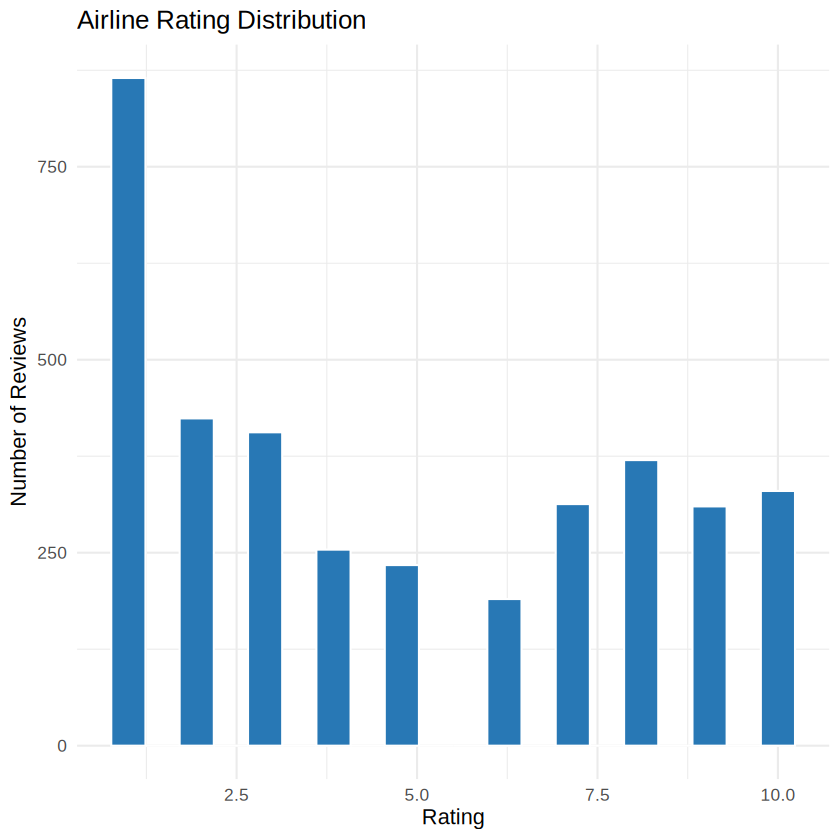

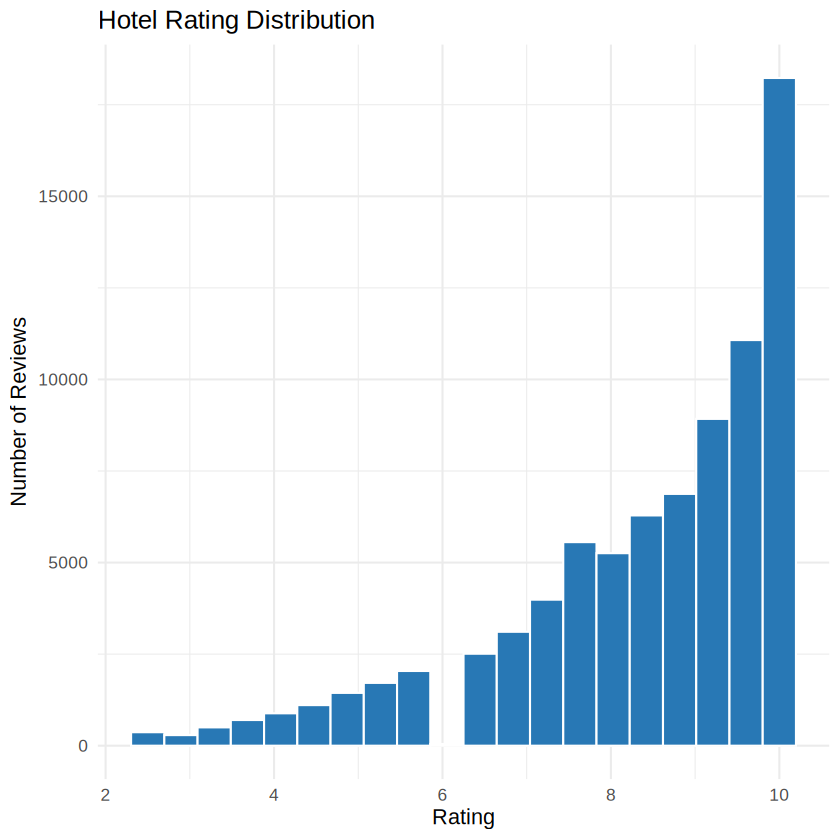

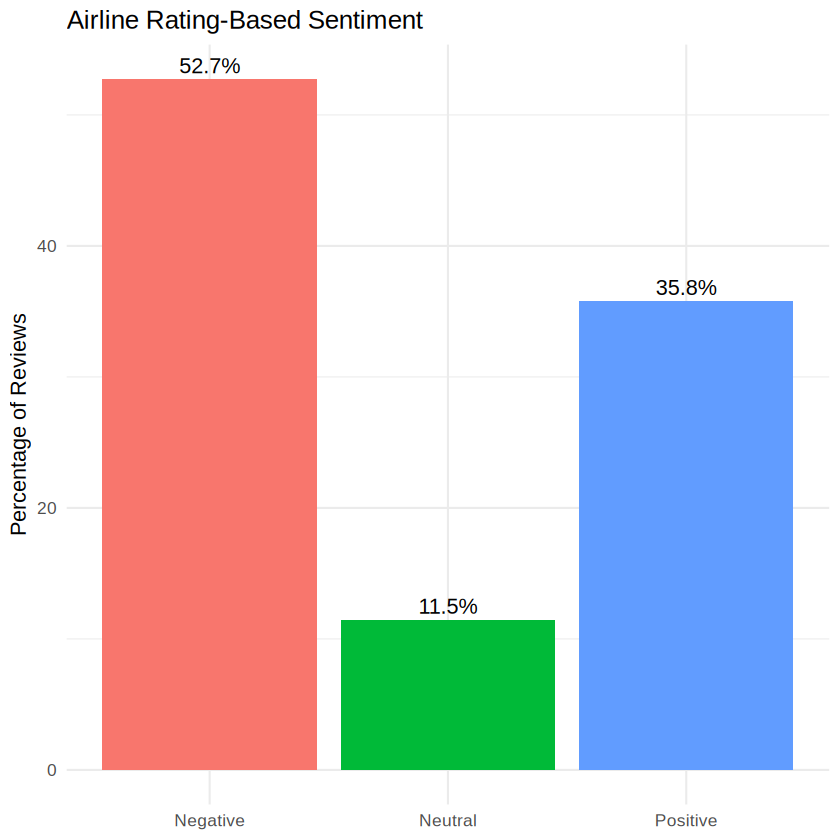

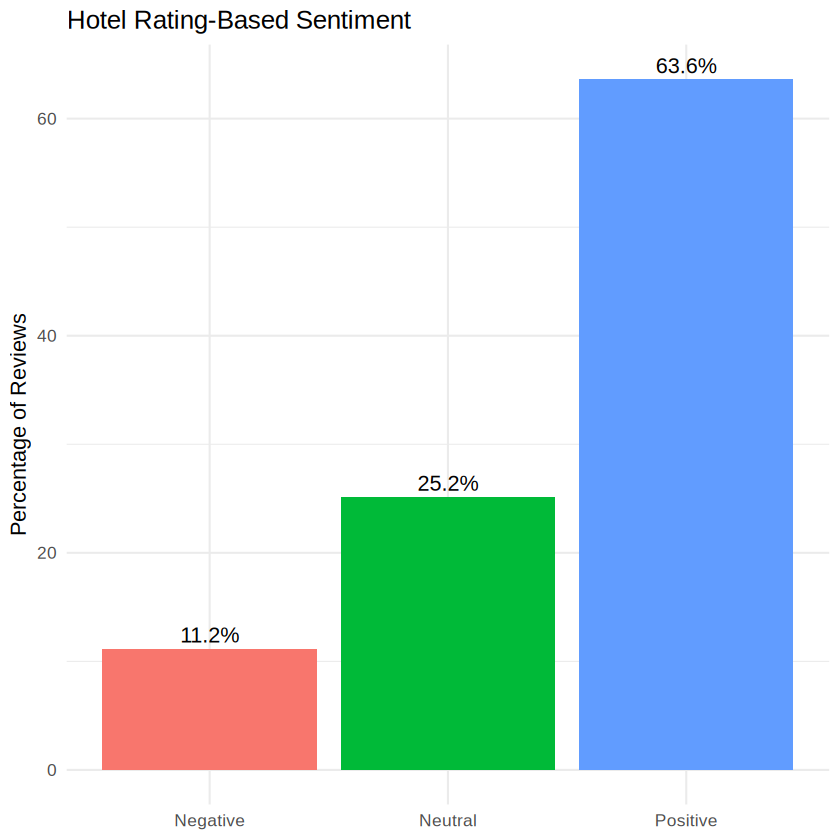

In [16]:
plot_rating <- function(df, label, filename) {
  p <- ggplot(df[!is.na(df$rating), ], aes(x = rating)) +
    geom_histogram(bins = 20, fill = "#2878B5", color = "white", na.rm = TRUE) +
    labs(title = paste(label, "Rating Distribution"), x = "Rating", y = "Number of Reviews") +
    theme_minimal(base_size = 13)
  print(p)
  ggsave(file.path(output_dir, filename), p, width = 8, height = 5, dpi = 150)
}

plot_sentiment <- function(df, label, filename) {
  z <- df |> dplyr::filter(!is.na(rating_group)) |> dplyr::count(rating_group) |> dplyr::mutate(percent = n / sum(n) * 100)
  p <- ggplot(z, aes(x = rating_group, y = percent, fill = rating_group)) +
    geom_col(show.legend = FALSE) +
    geom_text(aes(label = paste0(round(percent, 1), "%")), vjust = -0.4) +
    labs(title = paste(label, "Rating-Based Sentiment"), x = NULL, y = "Percentage of Reviews") +
    theme_minimal(base_size = 13)
  print(p)
  ggsave(file.path(output_dir, filename), p, width = 8, height = 5, dpi = 150)
}

plot_rating(airline, "Airline", "airline_rating_distribution.png")
plot_rating(hotel, "Hotel", "hotel_rating_distribution.png")
plot_sentiment(airline, "Airline", "airline_sentiment.png")
plot_sentiment(hotel, "Hotel", "hotel_sentiment.png")

### Step 7: Service and Category Subgroup Analysis

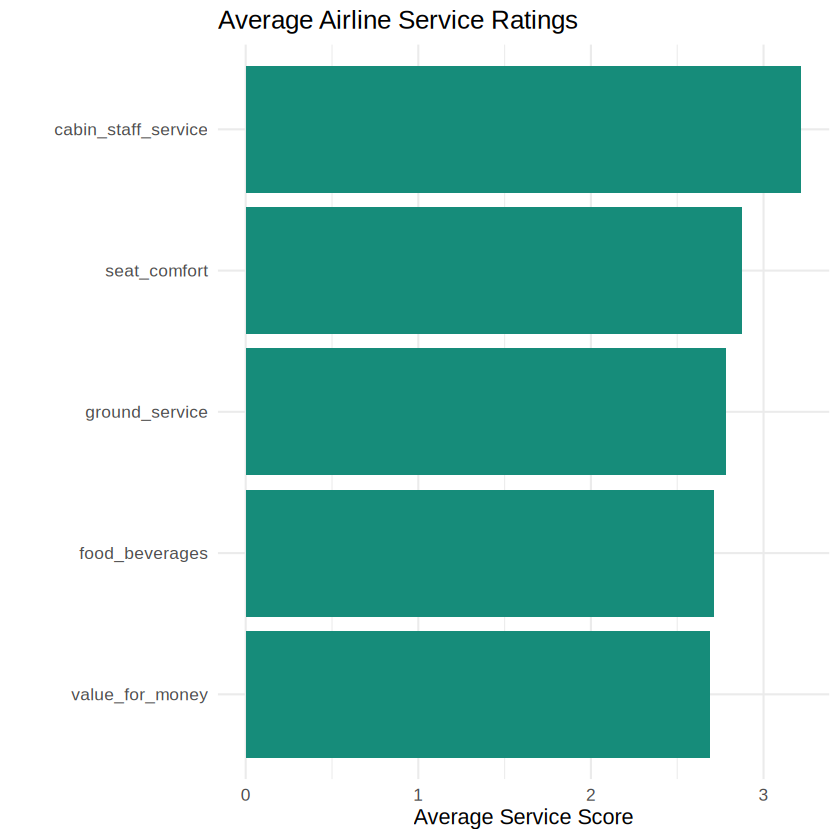

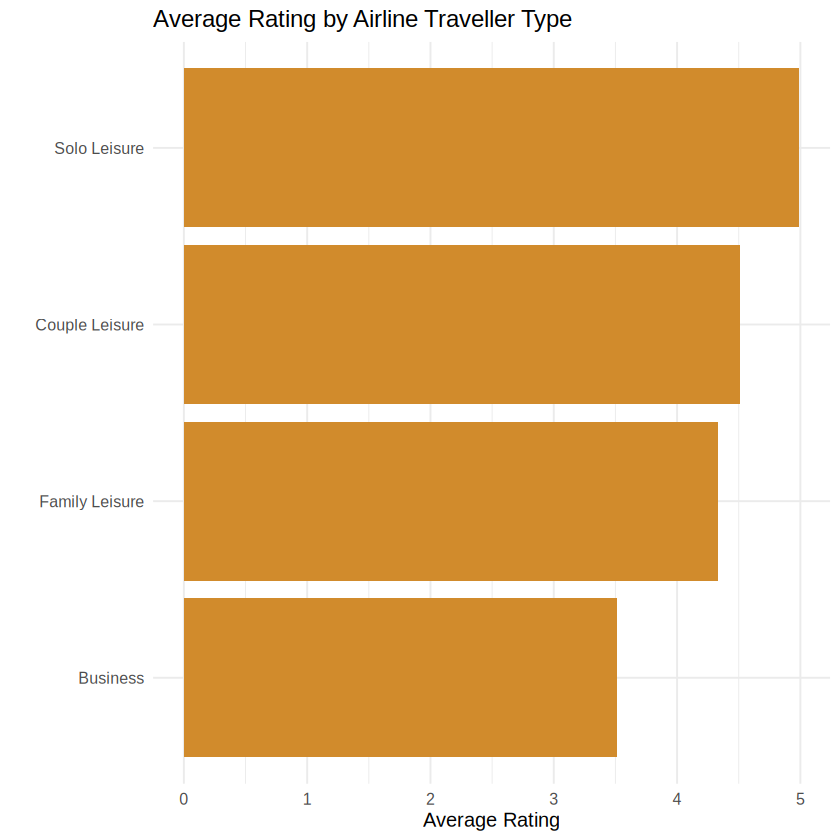

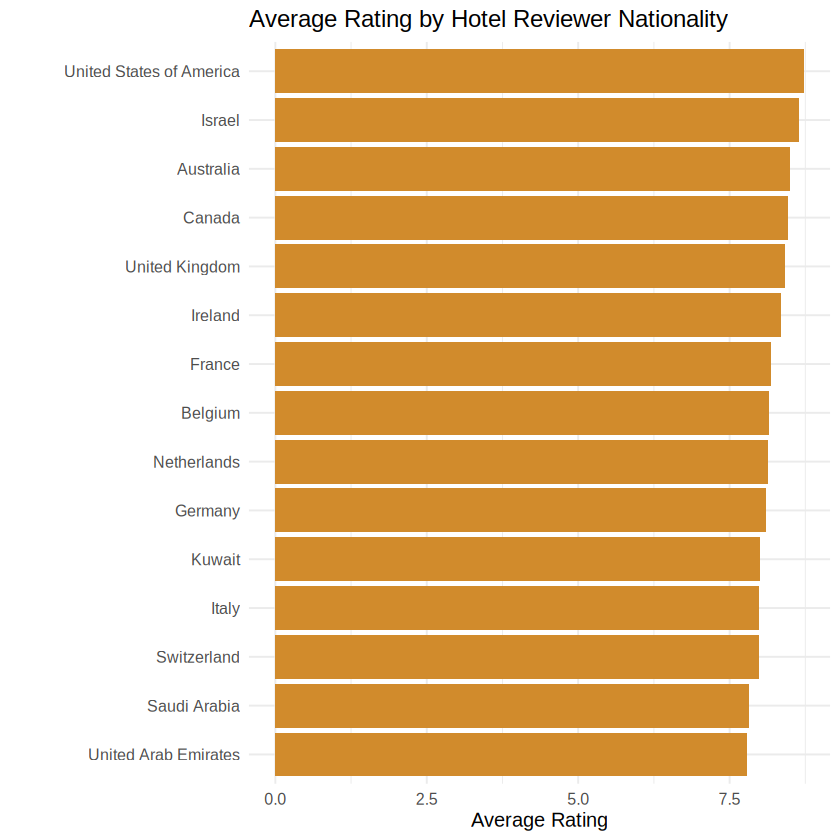

In [17]:
service_columns <- c("seat_comfort", "cabin_staff_service", "ground_service", "food_beverages", "value_for_money")
service_results <- data.frame(
  Service = service_columns,
  Average_score = sapply(service_columns, function(col) mean(airline[[col]], na.rm = TRUE)),
  Valid_reviews = sapply(service_columns, function(col) sum(!is.na(airline[[col]])))
)
service_results <- service_results[is.finite(service_results$Average_score), , drop = FALSE]

if (nrow(service_results)) {
  p_service <- ggplot(service_results, aes(x = reorder(Service, Average_score), y = Average_score)) +
    geom_col(fill = "#168C7A") + coord_flip() +
    labs(title = "Average Airline Service Ratings", x = NULL, y = "Average Service Score") +
    theme_minimal(base_size = 13)
  print(p_service)
  ggsave(file.path(output_dir, "airline_service_ratings.png"), p_service, width = 8, height = 5, dpi = 150)
}

category_analysis <- function(df, category_col, label) {
  if (!category_col %in% names(df)) return(NULL)
  z <- df |> dplyr::mutate(category = as.character(.data[[category_col]])) |>
    dplyr::filter(!is.na(category), nzchar(category), !is.na(rating)) |>
    dplyr::group_by(category) |>
    dplyr::summarise(reviews = dplyr::n(), average_rating = mean(rating), .groups = "drop") |>
    dplyr::filter(reviews >= 5) |> dplyr::arrange(desc(reviews)) |> head(15)

  if (nrow(z)) {
    p <- ggplot(z, aes(x = reorder(category, average_rating), y = average_rating)) +
      geom_col(fill = "#D18B2C") + coord_flip() +
      labs(title = paste("Average Rating by", label), x = NULL, y = "Average Rating") +
      theme_minimal(base_size = 12)
    print(p)
    ggsave(file.path(output_dir, paste0(gsub("[^a-z]+", "_", tolower(label)), "_category_ratings.png")), p, width = 9, height = 6, dpi = 150)
  }
  z
}

traveller_results <- category_analysis(airline, "traveller_type", "Airline Traveller Type")
nationality_results <- category_analysis(hotel, "nationality", "Hotel Reviewer Nationality")

### Step 8: Text Mining & Sentiment Lexicon Matching

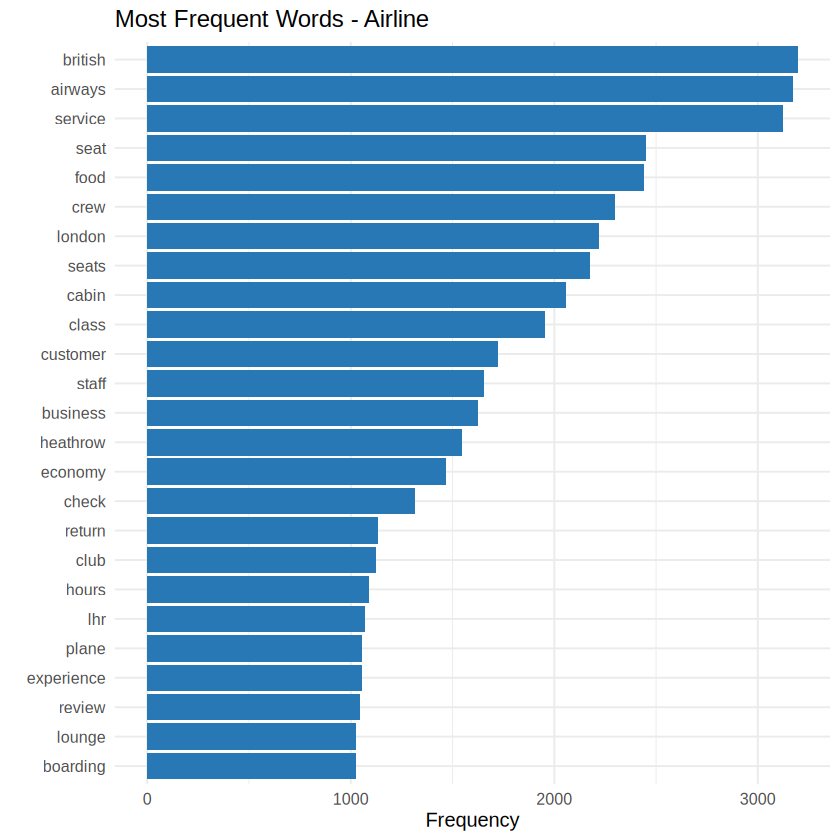

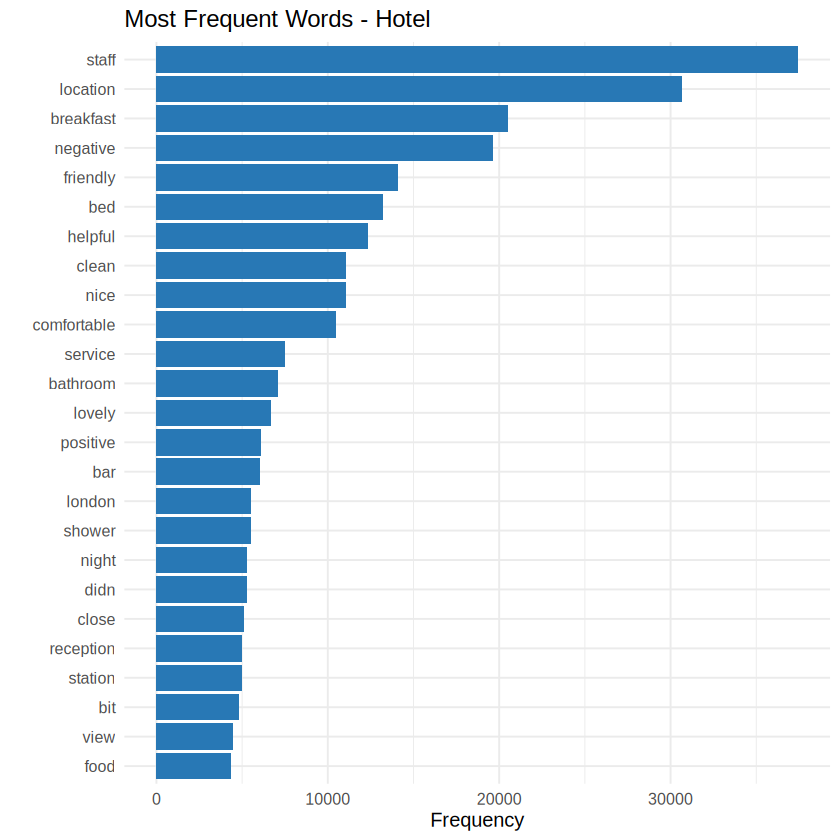

In [18]:
stop_words_extra <- c("flight", "flights", "airline", "hotel", "room", "rooms", "stay", "stayed", "would", "could", "also", "one", "two", "get", "got", "really", "much", "even", "still", "back", "said", "told", "day", "days", "time", "first", "last", "good", "great", "excellent", "bad", "poor")

mine_words <- function(df, label, filename) {
  tokens <- data.frame(text = df$review_text) |> tidytext::unnest_tokens(word, text) |>
    dplyr::filter(stringr::str_detect(word, "^[a-z]{3,}$"), !word %in% tidytext::stop_words$word, !word %in% stop_words_extra) |>
    dplyr::count(word, sort = TRUE)
  top_words <- head(tokens, 25)
  if (nrow(top_words)) {
    p <- ggplot(top_words, aes(x = reorder(word, n), y = n)) + geom_col(fill = "#2878B5") + coord_flip() +
      labs(title = paste("Most Frequent Words -", label), x = NULL, y = "Frequency") + theme_minimal(base_size = 12)
    print(p)
    ggsave(file.path(output_dir, filename), p, width = 8, height = 7, dpi = 150)
  }
  write.csv(top_words, file.path(output_dir, paste0(tolower(label), "_top_words.csv")), row.names = FALSE)
  top_words
}

airline_words <- mine_words(airline, "Airline", "airline_top_words.png")
hotel_words <- mine_words(hotel, "Hotel", "hotel_top_words.png")

### Step 9: Predictive Modeling (Regression and Correlation)

  Dataset Training_rows Testing_rows    MAE   RMSE Test_R2
1 Airline          2956          740 1.9331 2.3117  0.4607
  Dataset Training_rows Testing_rows    MAE  RMSE Test_R2
1   Hotel         16000         4000 1.2027 1.506  0.1981


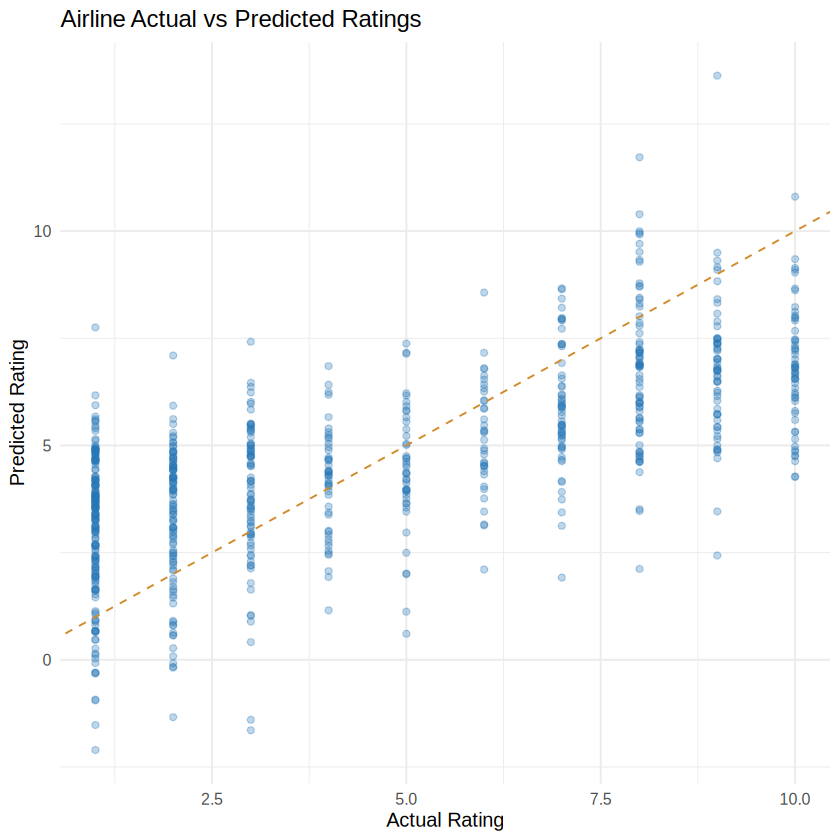

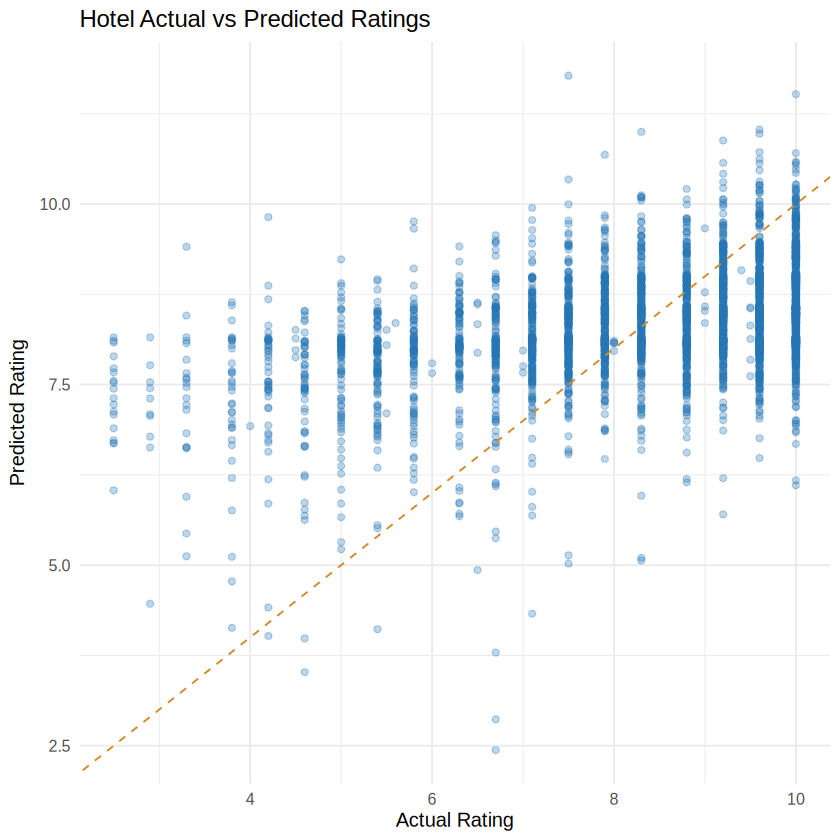

In [19]:
positive_words <- c("good", "great", "excellent", "amazing", "wonderful", "friendly", "helpful", "comfortable", "clean", "love", "best", "smooth", "enjoyed", "pleasant", "efficient", "professional", "fantastic", "perfect", "recommend", "happy")
negative_words <- c("bad", "poor", "terrible", "awful", "worst", "rude", "uncomfortable", "dirty", "delay", "delayed", "late", "broken", "slow", "expensive", "disappointed", "problem", "problems", "never", "horrible", "unhelpful")

score_text <- function(text) {
  words <- stringr::str_extract_all(tolower(text), "[a-z]+")[[1]]
  sum(words %in% positive_words) - sum(words %in% negative_words)
}

airline$sentiment_score <- vapply(airline$review_text, score_text, numeric(1))
hotel$sentiment_score <- vapply(hotel$review_text, score_text, numeric(1))
airline$word_count <- stringr::str_count(airline$review_text, "\\S+")
hotel$word_count <- stringr::str_count(hotel$review_text, "\\S+")

fit_rating_model <- function(df, label) {
  model_data <- df |> dplyr::select(rating, sentiment_score, word_count) |> dplyr::filter(is.finite(rating), is.finite(sentiment_score), is.finite(word_count))
  if (nrow(model_data) < 30) return(NULL)
  if (nrow(model_data) > 20000) model_data <- model_data |> dplyr::slice_sample(n = 20000)

  idx <- sample(seq_len(nrow(model_data)), size = floor(0.8 * nrow(model_data)))
  train <- model_data[idx, , drop = FALSE]
  test <- model_data[-idx, , drop = FALSE]

  fit <- lm(rating ~ sentiment_score + word_count, data = train)
  predictions <- predict(fit, newdata = test)

  metrics <- data.frame(
    Dataset = label, Training_rows = nrow(train), Testing_rows = nrow(test),
    MAE = round(mean(abs(test$rating - predictions)), 4), RMSE = round(sqrt(mean((test$rating - predictions)^2)), 4),
    Test_R2 = round(1 - sum((test$rating - predictions)^2) / sum((test$rating - mean(test$rating))^2), 4)
  )
  print(metrics)

  p <- ggplot(data.frame(Actual = test$rating, Predicted = as.numeric(predictions)), aes(x = Actual, y = Predicted)) +
    geom_point(alpha = 0.3, color = "#2878B5") + geom_abline(slope = 1, intercept = 0, linetype = "dashed", color = "#D18B2C") +
    labs(title = paste(label, "Actual vs Predicted Ratings"), x = "Actual Rating", y = "Predicted Rating") + theme_minimal(base_size = 12)
  print(p)
  ggsave(file.path(output_dir, paste0(tolower(label), "_actual_vs_predicted.png")), p, width = 7, height = 6, dpi = 150)
  list(model = fit, metrics = metrics)
}

airline_model <- fit_rating_model(airline, "Airline")
hotel_model <- fit_rating_model(hotel, "Hotel")

### Step 10: Generate Recommendations and Save Final Artifacts

In [20]:
make_recommendations <- function(df, label) {
  valid <- df |> dplyr::filter(!is.na(rating))
  positive_pct <- mean(valid$rating_group == "Positive") * 100
  negative_pct <- mean(valid$rating_group == "Negative") * 100

  cat("\n===============", label, "INSIGHTS ================\n")
  cat("Average rating:", round(mean(valid$rating), 2), "\n")
  if (negative_pct >= 30) {
    cat("Recommendation: investigate recurring complaints and service failures.\n")
  } else {
    cat("Recommendation: preserve factors associated with strong ratings.\n")
  }
}

make_recommendations(airline, "Airline")
make_recommendations(hotel, "Hotel")

# Save clean data and compress outputs
write.csv(airline, file.path(output_dir, "airline_cleaned.csv"), row.names = FALSE, na = "")
write.csv(hotel, file.path(output_dir, "hotel_cleaned.csv"), row.names = FALSE, na = "")

zip_output <- "/content/review_analysis_outputs.zip"
if (file.exists(zip_output)) file.remove(zip_output)
utils::zip(zipfile = zip_output, files = list.files(output_dir, full.names = FALSE), flags = "-r", extras = "-j")
cat("\nDownload the output archive from:", zip_output, "\n")


=============== Airline INSIGHTS ================
Average rating: 4.73 
Recommendation: investigate recurring complaints and service failures.

=============== Hotel INSIGHTS ================
Average rating: 8.34 
Recommendation: preserve factors associated with strong ratings.

Download the output archive from: /content/review_analysis_outputs.zip 


In [21]:

# ================================================================
# 17. ACTIONABLE RECOMMENDATIONS FROM CUSTOMER REVIEWS
# ================================================================

# A. AIRLINE SERVICE PERFORMANCE
cat("\n============================================\n")
cat("AIRLINE SERVICE IMPROVEMENT RECOMMENDATIONS\n")
cat("============================================\n")

service_labels <- c(
  seat_comfort = "Seat Comfort",
  cabin_staff_service = "Cabin Staff Service",
  ground_service = "Ground Service",
  food_beverages = "Food and Beverages",
  value_for_money = "Value for Money"
)

service_results <- data.frame(
  service = names(service_labels),
  service_name = unname(service_labels),
  average_score = sapply(names(service_labels), function(x) {
    mean(airline[[x]], na.rm = TRUE)
  }),
  valid_reviews = sapply(names(service_labels), function(x) {
    sum(!is.na(airline[[x]]))
  }),
  stringsAsFactors = FALSE
)

service_results <- service_results |>
  dplyr::filter(
    is.finite(average_score),
    valid_reviews > 0
  ) |>
  dplyr::arrange(average_score)

cat("\n1. Average service ratings (lowest first):\n")
print(service_results)

if (nrow(service_results) > 0) {
  lowest <- service_results[1, ]

  cat("\nMAIN SERVICE FINDING:\n")
  cat(
    lowest$service_name,
    "has the lowest average score:",
    round(lowest$average_score, 2),
    "based on", lowest$valid_reviews, "valid ratings.\n"
  )

  cat("\nRECOMMENDATION:\n")

  if (lowest$service == "cabin_staff_service") {
    cat(
      "Prioritise cabin staff service improvement. Review passenger ",
      "complaints about staff behaviour, communication, responsiveness ",
      "and assistance. Provide targeted staff training and monitor ",
      "future service ratings.\n", sep = ""
    )
  } else if (lowest$service == "seat_comfort") {
    cat(
      "Prioritise seat comfort. Investigate passenger feedback about ",
      "seat space, cushioning, cleanliness and comfort, and assess ",
      "which improvements are feasible.\n", sep = ""
    )
  } else if (lowest$service == "ground_service") {
    cat(
      "Prioritise ground service. Investigate check-in, boarding, ",
      "airport assistance and delays where mentioned in reviews.\n",
      sep = ""
    )
  } else if (lowest$service == "food_beverages") {
    cat(
      "Prioritise food and beverages. Review complaints about food ",
      "quality, variety, temperature and availability.\n", sep = ""
    )
  } else if (lowest$service == "value_for_money") {
    cat(
      "Prioritise value for money. Examine whether passengers feel ",
      "that fares and additional charges match the service received.\n",
      sep = ""
    )
  }
} else {
  cat(
    "\nNo usable service scores were found. Check the source columns ",
    "and their numeric values before making a service recommendation.\n",
    sep = ""
  )
}

# B. CHECK WHAT LOW-RATED AIRLINE REVIEWS ACTUALLY MENTION
airline_issues <- list(
  "Cabin staff / crew" =
    "\\b(cabin crew|flight attendant|staff|crew|steward|stewardess)\\b",
  "Delays / punctuality" =
    "\\b(delay|delayed|late|cancelled|cancellation|rescheduled)\\b",
  "Baggage handling" =
    "\\b(baggage|luggage|suitcase|lost bag|damaged bag)\\b",
  "Seat comfort" =
    "\\b(seat|legroom|leg room|recline|uncomfortable)\\b",
  "Food / beverages" =
    "\\b(food|meal|beverage|drink|coffee|snack)\\b",
  "Customer support" =
    "\\b(customer service|support|complaint|refund|response)\\b",
  "Value / extra charges" =
    "\\b(overpriced|expensive|extra charge|hidden charge|value for money)\\b"
)

low_airline <- airline |>
  dplyr::filter(!is.na(rating), rating < 5)

cat("\nLOW-RATED AIRLINE REVIEWS:", nrow(low_airline), "\n")

if (nrow(low_airline) > 0) {
  airline_issue_results <- do.call(
    rbind,
    lapply(names(airline_issues), function(issue) {
      matched <- stringr::str_detect(
        tolower(low_airline$review_text),
        airline_issues[[issue]]
      )

      data.frame(
        Issue = issue,
        Matching_reviews = sum(matched, na.rm = TRUE),
        Percentage_of_low_rated_reviews =
          round(mean(matched, na.rm = TRUE) * 100, 1)
      )
    })
  )

  airline_issue_results <- airline_issue_results |>
    dplyr::arrange(dplyr::desc(Matching_reviews))

  cat("\nMOST COMMON TOPICS IN LOW-RATED AIRLINE REVIEWS:\n")
  print(airline_issue_results)

  top_issue <- airline_issue_results[1, ]

  if (top_issue$Matching_reviews > 0) {
    cat("\nREVIEW-BASED RECOMMENDATION:\n")
    cat(
      top_issue$Issue, "is the most frequently detected topic among ",
      "low-rated airline reviews (",
      top_issue$Matching_reviews, " reviews; ",
      top_issue$Percentage_of_low_rated_reviews, "% of low-rated reviews).\n",
      sep = ""
    )
    cat(
      "Investigate these reviews, identify the specific causes of ",
      "dissatisfaction, implement a targeted improvement, and track ",
      "whether subsequent ratings improve.\n", sep = ""
    )
  } else {
    cat(
      "\nNo listed issue keywords were detected in the low-rated ",
      "reviews. Manually inspect negative reviews to identify other ",
      "recurring concerns.\n", sep = ""
    )
  }

  write.csv(
    airline_issue_results,
    file.path(output_dir, "airline_complaint_topics.csv"),
    row.names = FALSE
  )
} else {
  cat(
    "No airline reviews with ratings below 5 were found. ",
    "No low-rating complaint analysis can be produced with this threshold.\n"
  )
}

# C. HOTEL REVIEW ISSUES
cat("\n============================================\n")
cat("HOTEL SERVICE IMPROVEMENT RECOMMENDATIONS\n")
cat("============================================\n")

hotel_issues <- list(
  "Hotel staff" =
    "\\b(staff|receptionist|manager|service|rude|unhelpful)\\b",
  "Cleanliness" =
    "\\b(clean|dirty|cleanliness|dusty|stain|hygiene)\\b",
  "Room comfort / facilities" =
    "\\b(room|bed|mattress|noise|air conditioning|bathroom|shower)\\b",
  "Location / transport" =
    "\\b(location|transport|distance|station|airport|parking)\\b",
  "Food / breakfast" =
    "\\b(food|breakfast|restaurant|meal|dinner)\\b",
  "Price / value" =
    "\\b(price|expensive|overpriced|value|cost)\\b"
)

low_hotel <- hotel |>
  dplyr::filter(!is.na(rating), rating < 6)

cat("\nLOW-RATED HOTEL REVIEWS:", nrow(low_hotel), "\n")

if (nrow(low_hotel) > 0) {
  hotel_issue_results <- do.call(
    rbind,
    lapply(names(hotel_issues), function(issue) {
      matched <- stringr::str_detect(
        tolower(low_hotel$review_text),
        hotel_issues[[issue]]
      )

      data.frame(
        Issue = issue,
        Matching_reviews = sum(matched, na.rm = TRUE),
        Percentage_of_low_rated_reviews =
          round(mean(matched, na.rm = TRUE) * 100, 1)
      )
    })
  )

  hotel_issue_results <- hotel_issue_results |>
    dplyr::arrange(dplyr::desc(Matching_reviews))

  cat("\nMOST COMMON TOPICS IN LOW-RATED HOTEL REVIEWS:\n")
  print(hotel_issue_results)

  top_hotel_issue <- hotel_issue_results[1, ]

  if (top_hotel_issue$Matching_reviews > 0) {
    cat("\nHOTEL RECOMMENDATION:\n")
    cat(
      top_hotel_issue$Issue, "is the most frequently detected topic ",
      "among low-rated hotel reviews (",
      top_hotel_issue$Matching_reviews, " reviews; ",
      top_hotel_issue$Percentage_of_low_rated_reviews,
      "% of low-rated reviews).\n", sep = ""
    )
    cat(
      "Review the matching customer comments, identify the underlying ",
      "problem, prioritise corrective action, and monitor later ratings.\n",
      sep = ""
    )
  }

  write.csv(
    hotel_issue_results,
    file.path(output_dir, "hotel_complaint_topics.csv"),
    row.names = FALSE
  )
} else {
  cat(
    "No hotel reviews below the selected rating threshold were found.\n"
  )
}

# D. EXPORT SERVICE RATINGS FOR YOUR REPORT
write.csv(
  service_results,
  file.path(output_dir, "airline_service_recommendations.csv"),
  row.names = FALSE
)

cat("\n============================================\n")
cat("RECOMMENDATION ANALYSIS COMPLETE\n")
cat("Results saved in:", output_dir, "\n")
cat("============================================\n")



AIRLINE SERVICE IMPROVEMENT RECOMMENDATIONS

1. Average service ratings (lowest first):
                                service        service_name average_score
value_for_money         value_for_money     Value for Money      2.688378
food_beverages           food_beverages  Food and Beverages      2.713122
ground_service           ground_service      Ground Service      2.784238
seat_comfort               seat_comfort        Seat Comfort      2.875314
cabin_staff_service cabin_staff_service Cabin Staff Service      3.219532
                    valid_reviews
value_for_money              3700
food_beverages               3315
ground_service               2855
seat_comfort                 3585
cabin_staff_service          3635

MAIN SERVICE FINDING:
Value for Money has the lowest average score: 2.69 based on 3700 valid ratings.

RECOMMENDATION:
Prioritise value for money. Examine whether passengers feel that fares and additional charges match the service received.

LOW-RATED AIRLINE RE

In [22]:

# ================================================================
# 17. ACTIONABLE RECOMMENDATIONS FROM CUSTOMER REVIEWS
# ================================================================

# A. AIRLINE SERVICE PERFORMANCE
cat("\n============================================\n")
cat("AIRLINE SERVICE IMPROVEMENT RECOMMENDATIONS\n")
cat("============================================\n")

service_labels <- c(
  seat_comfort = "Seat Comfort",
  cabin_staff_service = "Cabin Staff Service",
  ground_service = "Ground Service",
  food_beverages = "Food and Beverages",
  value_for_money = "Value for Money"
)

service_results <- data.frame(
  service = names(service_labels),
  service_name = unname(service_labels),
  average_score = sapply(names(service_labels), function(x) {
    mean(airline[[x]], na.rm = TRUE)
  }),
  valid_reviews = sapply(names(service_labels), function(x) {
    sum(!is.na(airline[[x]]))
  }),
  stringsAsFactors = FALSE
)

service_results <- service_results |>
  dplyr::filter(
    is.finite(average_score),
    valid_reviews > 0
  ) |>
  dplyr::arrange(average_score)

cat("\n1. Average service ratings (lowest first):\n")
print(service_results)

if (nrow(service_results) > 0) {
  lowest <- service_results[1, ]

  cat("\nMAIN SERVICE FINDING:\n")
  cat(
    lowest$service_name,
    "has the lowest average score:",
    round(lowest$average_score, 2),
    "based on", lowest$valid_reviews, "valid ratings.\n"
  )

  cat("\nRECOMMENDATION:\n")

  if (lowest$service == "cabin_staff_service") {
    cat(
      "Prioritise cabin staff service improvement. Review passenger ",
      "complaints about staff behaviour, communication, responsiveness ",
      "and assistance. Provide targeted staff training and monitor ",
      "future service ratings.\n", sep = ""
    )
  } else if (lowest$service == "seat_comfort") {
    cat(
      "Prioritise seat comfort. Investigate passenger feedback about ",
      "seat space, cushioning, cleanliness and comfort, and assess ",
      "which improvements are feasible.\n", sep = ""
    )
  } else if (lowest$service == "ground_service") {
    cat(
      "Prioritise ground service. Investigate check-in, boarding, ",
      "airport assistance and delays where mentioned in reviews.\n",
      sep = ""
    )
  } else if (lowest$service == "food_beverages") {
    cat(
      "Prioritise food and beverages. Review complaints about food ",
      "quality, variety, temperature and availability.\n", sep = ""
    )
  } else if (lowest$service == "value_for_money") {
    cat(
      "Prioritise value for money. Examine whether passengers feel ",
      "that fares and additional charges match the service received.\n",
      sep = ""
    )
  }
} else {
  cat(
    "\nNo usable service scores were found. Check the source columns ",
    "and their numeric values before making a service recommendation.\n",
    sep = ""
  )
}

# B. CHECK WHAT LOW-RATED AIRLINE REVIEWS ACTUALLY MENTION
airline_issues <- list(
  "Cabin staff / crew" =
    "\\b(cabin crew|flight attendant|staff|crew|steward|stewardess)\\b",
  "Delays / punctuality" =
    "\\b(delay|delayed|late|cancelled|cancellation|rescheduled)\\b",
  "Baggage handling" =
    "\\b(baggage|luggage|suitcase|lost bag|damaged bag)\\b",
  "Seat comfort" =
    "\\b(seat|legroom|leg room|recline|uncomfortable)\\b",
  "Food / beverages" =
    "\\b(food|meal|beverage|drink|coffee|snack)\\b",
  "Customer support" =
    "\\b(customer service|support|complaint|refund|response)\\b",
  "Value / extra charges" =
    "\\b(overpriced|expensive|extra charge|hidden charge|value for money)\\b"
)

low_airline <- airline |>
  dplyr::filter(!is.na(rating), rating < 5)

cat("\nLOW-RATED AIRLINE REVIEWS:", nrow(low_airline), "\n")

if (nrow(low_airline) > 0) {
  airline_issue_results <- do.call(
    rbind,
    lapply(names(airline_issues), function(issue) {
      matched <- stringr::str_detect(
        tolower(low_airline$review_text),
        airline_issues[[issue]]
      )

      data.frame(
        Issue = issue,
        Matching_reviews = sum(matched, na.rm = TRUE),
        Percentage_of_low_rated_reviews =
          round(mean(matched, na.rm = TRUE) * 100, 1)
      )
    })
  )

  airline_issue_results <- airline_issue_results |>
    dplyr::arrange(dplyr::desc(Matching_reviews))

  cat("\nMOST COMMON TOPICS IN LOW-RATED AIRLINE REVIEWS:\n")
  print(airline_issue_results)

  top_issue <- airline_issue_results[1, ]

  if (top_issue$Matching_reviews > 0) {
    cat("\nREVIEW-BASED RECOMMENDATION:\n")
    cat(
      top_issue$Issue, "is the most frequently detected topic among ",
      "low-rated airline reviews (",
      top_issue$Matching_reviews, " reviews; ",
      top_issue$Percentage_of_low_rated_reviews, "% of low-rated reviews).\n",
      sep = ""
    )
    cat(
      "Investigate these reviews, identify the specific causes of ",
      "dissatisfaction, implement a targeted improvement, and track ",
      "whether subsequent ratings improve.\n", sep = ""
    )
  } else {
    cat(
      "\nNo listed issue keywords were detected in the low-rated ",
      "reviews. Manually inspect negative reviews to identify other ",
      "recurring concerns.\n", sep = ""
    )
  }

  write.csv(
    airline_issue_results,
    file.path(output_dir, "airline_complaint_topics.csv"),
    row.names = FALSE
  )
} else {
  cat(
    "No airline reviews with ratings below 5 were found. ",
    "No low-rating complaint analysis can be produced with this threshold.\n"
  )
}

# C. HOTEL REVIEW ISSUES
cat("\n============================================\n")
cat("HOTEL SERVICE IMPROVEMENT RECOMMENDATIONS\n")
cat("============================================\n")

hotel_issues <- list(
  "Hotel staff" =
    "\\b(staff|receptionist|manager|service|rude|unhelpful)\\b",
  "Cleanliness" =
    "\\b(clean|dirty|cleanliness|dusty|stain|hygiene)\\b",
  "Room comfort / facilities" =
    "\\b(room|bed|mattress|noise|air conditioning|bathroom|shower)\\b",
  "Location / transport" =
    "\\b(location|transport|distance|station|airport|parking)\\b",
  "Food / breakfast" =
    "\\b(food|breakfast|restaurant|meal|dinner)\\b",
  "Price / value" =
    "\\b(price|expensive|overpriced|value|cost)\\b"
)

low_hotel <- hotel |>
  dplyr::filter(!is.na(rating), rating < 6)

cat("\nLOW-RATED HOTEL REVIEWS:", nrow(low_hotel), "\n")

if (nrow(low_hotel) > 0) {
  hotel_issue_results <- do.call(
    rbind,
    lapply(names(hotel_issues), function(issue) {
      matched <- stringr::str_detect(
        tolower(low_hotel$review_text),
        hotel_issues[[issue]]
      )

      data.frame(
        Issue = issue,
        Matching_reviews = sum(matched, na.rm = TRUE),
        Percentage_of_low_rated_reviews =
          round(mean(matched, na.rm = TRUE) * 100, 1)
      )
    })
  )

  hotel_issue_results <- hotel_issue_results |>
    dplyr::arrange(dplyr::desc(Matching_reviews))

  cat("\nMOST COMMON TOPICS IN LOW-RATED HOTEL REVIEWS:\n")
  print(hotel_issue_results)

  top_hotel_issue <- hotel_issue_results[1, ]

  if (top_hotel_issue$Matching_reviews > 0) {
    cat("\nHOTEL RECOMMENDATION:\n")
    cat(
      top_hotel_issue$Issue, "is the most frequently detected topic ",
      "among low-rated hotel reviews (",
      top_hotel_issue$Matching_reviews, " reviews; ",
      top_hotel_issue$Percentage_of_low_rated_reviews,
      "% of low-rated reviews).\n", sep = ""
    )
    cat(
      "Review the matching customer comments, identify the underlying ",
      "problem, prioritise corrective action, and monitor later ratings.\n",
      sep = ""
    )
  }

  write.csv(
    hotel_issue_results,
    file.path(output_dir, "hotel_complaint_topics.csv"),
    row.names = FALSE
  )
} else {
  cat(
    "No hotel reviews below the selected rating threshold were found.\n"
  )
}

# D. EXPORT SERVICE RATINGS FOR YOUR REPORT
write.csv(
  service_results,
  file.path(output_dir, "airline_service_recommendations.csv"),
  row.names = FALSE
)

cat("\n============================================\n")
cat("RECOMMENDATION ANALYSIS COMPLETE\n")
cat("Results saved in:", output_dir, "\n")
cat("============================================\n")

# ================================================================
# 17. ACTIONABLE RECOMMENDATIONS FROM CUSTOMER REVIEWS
# ================================================================

# A. AIRLINE SERVICE PERFORMANCE
cat("\n============================================\n")
cat("AIRLINE SERVICE IMPROVEMENT RECOMMENDATIONS\n")
cat("============================================\n")

service_labels <- c(
  seat_comfort = "Seat Comfort",
  cabin_staff_service = "Cabin Staff Service",
  ground_service = "Ground Service",
  food_beverages = "Food and Beverages",
  value_for_money = "Value for Money"
)

service_results <- data.frame(
  service = names(service_labels),
  service_name = unname(service_labels),
  average_score = sapply(names(service_labels), function(x) {
    mean(airline[[x]], na.rm = TRUE)
  }),
  valid_reviews = sapply(names(service_labels), function(x) {
    sum(!is.na(airline[[x]]))
  }),
  stringsAsFactors = FALSE
)

service_results <- service_results |>
  dplyr::filter(
    is.finite(average_score),
    valid_reviews > 0
  ) |>
  dplyr::arrange(average_score)

cat("\n1. Average service ratings (lowest first):\n")
print(service_results)

if (nrow(service_results) > 0) {
  lowest <- service_results[1, ]

  cat("\nMAIN SERVICE FINDING:\n")
  cat(
    lowest$service_name,
    "has the lowest average score:",
    round(lowest$average_score, 2),
    "based on", lowest$valid_reviews, "valid ratings.\n"
  )

  cat("\nRECOMMENDATION:\n")

  if (lowest$service == "cabin_staff_service") {
    cat(
      "Prioritise cabin staff service improvement. Review passenger ",
      "complaints about staff behaviour, communication, responsiveness ",
      "and assistance. Provide targeted staff training and monitor ",
      "future service ratings.\n", sep = ""
    )
  } else if (lowest$service == "seat_comfort") {
    cat(
      "Prioritise seat comfort. Investigate passenger feedback about ",
      "seat space, cushioning, cleanliness and comfort, and assess ",
      "which improvements are feasible.\n", sep = ""
    )
  } else if (lowest$service == "ground_service") {
    cat(
      "Prioritise ground service. Investigate check-in, boarding, ",
      "airport assistance and delays where mentioned in reviews.\n",
      sep = ""
    )
  } else if (lowest$service == "food_beverages") {
    cat(
      "Prioritise food and beverages. Review complaints about food ",
      "quality, variety, temperature and availability.\n", sep = ""
    )
  } else if (lowest$service == "value_for_money") {
    cat(
      "Prioritise value for money. Examine whether passengers feel ",
      "that fares and additional charges match the service received.\n",
      sep = ""
    )
  }
} else {
  cat(
    "\nNo usable service scores were found. Check the source columns ",
    "and their numeric values before making a service recommendation.\n",
    sep = ""
  )
}

# B. CHECK WHAT LOW-RATED AIRLINE REVIEWS ACTUALLY MENTION
airline_issues <- list(
  "Cabin staff / crew" =
    "\\b(cabin crew|flight attendant|staff|crew|steward|stewardess)\\b",
  "Delays / punctuality" =
    "\\b(delay|delayed|late|cancelled|cancellation|rescheduled)\\b",
  "Baggage handling" =
    "\\b(baggage|luggage|suitcase|lost bag|damaged bag)\\b",
  "Seat comfort" =
    "\\b(seat|legroom|leg room|recline|uncomfortable)\\b",
  "Food / beverages" =
    "\\b(food|meal|beverage|drink|coffee|snack)\\b",
  "Customer support" =
    "\\b(customer service|support|complaint|refund|response)\\b",
  "Value / extra charges" =
    "\\b(overpriced|expensive|extra charge|hidden charge|value for money)\\b"
)

low_airline <- airline |>
  dplyr::filter(!is.na(rating), rating < 5)

cat("\nLOW-RATED AIRLINE REVIEWS:", nrow(low_airline), "\n")

if (nrow(low_airline) > 0) {
  airline_issue_results <- do.call(
    rbind,
    lapply(names(airline_issues), function(issue) {
      matched <- stringr::str_detect(
        tolower(low_airline$review_text),
        airline_issues[[issue]]
      )

      data.frame(
        Issue = issue,
        Matching_reviews = sum(matched, na.rm = TRUE),
        Percentage_of_low_rated_reviews =
          round(mean(matched, na.rm = TRUE) * 100, 1)
      )
    })
  )

  airline_issue_results <- airline_issue_results |>
    dplyr::arrange(dplyr::desc(Matching_reviews))

  cat("\nMOST COMMON TOPICS IN LOW-RATED AIRLINE REVIEWS:\n")
  print(airline_issue_results)

  top_issue <- airline_issue_results[1, ]

  if (top_issue$Matching_reviews > 0) {
    cat("\nREVIEW-BASED RECOMMENDATION:\n")
    cat(
      top_issue$Issue, "is the most frequently detected topic among ",
      "low-rated airline reviews (",
      top_issue$Matching_reviews, " reviews; ",
      top_issue$Percentage_of_low_rated_reviews, "% of low-rated reviews).\n",
      sep = ""
    )
    cat(
      "Investigate these reviews, identify the specific causes of ",
      "dissatisfaction, implement a targeted improvement, and track ",
      "whether subsequent ratings improve.\n", sep = ""
    )
  } else {
    cat(
      "\nNo listed issue keywords were detected in the low-rated ",
      "reviews. Manually inspect negative reviews to identify other ",
      "recurring concerns.\n", sep = ""
    )
  }

  write.csv(
    airline_issue_results,
    file.path(output_dir, "airline_complaint_topics.csv"),
    row.names = FALSE
  )
} else {
  cat(
    "No airline reviews with ratings below 5 were found. ",
    "No low-rating complaint analysis can be produced with this threshold.\n"
  )
}

# C. HOTEL REVIEW ISSUES
cat("\n============================================\n")
cat("HOTEL SERVICE IMPROVEMENT RECOMMENDATIONS\n")
cat("============================================\n")

hotel_issues <- list(
  "Hotel staff" =
    "\\b(staff|receptionist|manager|service|rude|unhelpful)\\b",
  "Cleanliness" =
    "\\b(clean|dirty|cleanliness|dusty|stain|hygiene)\\b",
  "Room comfort / facilities" =
    "\\b(room|bed|mattress|noise|air conditioning|bathroom|shower)\\b",
  "Location / transport" =
    "\\b(location|transport|distance|station|airport|parking)\\b",
  "Food / breakfast" =
    "\\b(food|breakfast|restaurant|meal|dinner)\\b",
  "Price / value" =
    "\\b(price|expensive|overpriced|value|cost)\\b"
)

low_hotel <- hotel |>
  dplyr::filter(!is.na(rating), rating < 6)

cat("\nLOW-RATED HOTEL REVIEWS:", nrow(low_hotel), "\n")

if (nrow(low_hotel) > 0) {
  hotel_issue_results <- do.call(
    rbind,
    lapply(names(hotel_issues), function(issue) {
      matched <- stringr::str_detect(
        tolower(low_hotel$review_text),
        hotel_issues[[issue]]
      )

      data.frame(
        Issue = issue,
        Matching_reviews = sum(matched, na.rm = TRUE),
        Percentage_of_low_rated_reviews =
          round(mean(matched, na.rm = TRUE) * 100, 1)
      )
    })
  )

  hotel_issue_results <- hotel_issue_results |>
    dplyr::arrange(dplyr::desc(Matching_reviews))

  cat("\nMOST COMMON TOPICS IN LOW-RATED HOTEL REVIEWS:\n")
  print(hotel_issue_results)

  top_hotel_issue <- hotel_issue_results[1, ]

  if (top_hotel_issue$Matching_reviews > 0) {
    cat("\nHOTEL RECOMMENDATION:\n")
    cat(
      top_hotel_issue$Issue, "is the most frequently detected topic ",
      "among low-rated hotel reviews (",
      top_hotel_issue$Matching_reviews, " reviews; ",
      top_hotel_issue$Percentage_of_low_rated_reviews,
      "% of low-rated reviews).\n", sep = ""
    )
    cat(
      "Review the matching customer comments, identify the underlying ",
      "problem, prioritise corrective action, and monitor later ratings.\n",
      sep = ""
    )
  }

  write.csv(
    hotel_issue_results,
    file.path(output_dir, "hotel_complaint_topics.csv"),
    row.names = FALSE
  )
} else {
  cat(
    "No hotel reviews below the selected rating threshold were found.\n"
  )
}

# D. EXPORT SERVICE RATINGS FOR YOUR REPORT
write.csv(
  service_results,
  file.path(output_dir, "airline_service_recommendations.csv"),
  row.names = FALSE
)

cat("\n============================================\n")
cat("RECOMMENDATION ANALYSIS COMPLETE\n")
cat("Results saved in:", output_dir, "\n")
cat("============================================\n")



AIRLINE SERVICE IMPROVEMENT RECOMMENDATIONS

1. Average service ratings (lowest first):
                                service        service_name average_score
value_for_money         value_for_money     Value for Money      2.688378
food_beverages           food_beverages  Food and Beverages      2.713122
ground_service           ground_service      Ground Service      2.784238
seat_comfort               seat_comfort        Seat Comfort      2.875314
cabin_staff_service cabin_staff_service Cabin Staff Service      3.219532
                    valid_reviews
value_for_money              3700
food_beverages               3315
ground_service               2855
seat_comfort                 3585
cabin_staff_service          3635

MAIN SERVICE FINDING:
Value for Money has the lowest average score: 2.69 based on 3700 valid ratings.

RECOMMENDATION:
Prioritise value for money. Examine whether passengers feel that fares and additional charges match the service received.

LOW-RATED AIRLINE RE

In [24]:

# ================================================================
# AIRLINE & HOTEL REVIEW TEXT MINING
# INTERACTIVE HTML REPORT - R ONLY
# ================================================================

# ================== 1. SET YOUR PATHS HERE ========================
# OPTION A: If uploading a ZIP file directly to Colab
zip_path <- "/content/review_project_extracted/archive"

# OPTION B: If you already extracted the CSVs, put their direct paths here:
airline_csv_path <- "/content/BA_AirlineReviews.csv"
hotel_csv_path   <- "/content/Hotel_Reviews.csv"

output_dir <- "/content/interactive_review_report"
dir.create(output_dir, recursive = TRUE, showWarnings = FALSE)

# ================== 2. INSTALL & LOAD PACKAGES ====================
packages <- c(
  "readr", "dplyr", "stringr", "tidyr", "ggplot2",
  "plotly", "DT", "htmltools", "htmlwidgets", "jsonlite"
)

for (p in packages) {
  if (!requireNamespace(p, quietly = TRUE)) {
    install.packages(p, repos = "https://cloud.r-project.org")
  }
}
invisible(lapply(packages, library, character.only = TRUE))

set.seed(42)

# ================== 3. LOAD THE CSV FILES ========================
if (nzchar(zip_path) && file.exists(zip_path)) {
  extract_dir <- "/content/review_project_extracted"
  dir.create(extract_dir, recursive = TRUE, showWarnings = FALSE)

  # Suppress unzip warnings safely
  suppressWarnings(unzip(zip_path, exdir = extract_dir))

  csv_files <- list.files(
    extract_dir, recursive = TRUE, full.names = TRUE,
    pattern = "\\.csv$", ignore.case = TRUE
  )

  if (!nzchar(airline_csv_path)) {
    x <- csv_files[tolower(basename(csv_files)) == "ba_airlinereviews.csv"]
    if (length(x)) airline_csv_path <- x[1]
  }

  if (!nzchar(hotel_csv_path)) {
    x <- csv_files[tolower(basename(csv_files)) == "hotel_reviews.csv"]
    if (length(x)) hotel_csv_path <- x[1]
  }
}

if (!file.exists(airline_csv_path) || !file.exists(hotel_csv_path)) {
  stop(
    "Could not find both CSV files. Check zip_path, ",
    "airline_csv_path and hotel_csv_path."
  )
}

read_csv_safe <- function(path) {
  readr::read_csv(
    path, show_col_types = FALSE,
    name_repair = "unique", guess_max = 10000
  )
}

airline_raw <- read_csv_safe(airline_csv_path)
hotel_raw   <- read_csv_safe(hotel_csv_path)

cat("Airline raw dimensions:", dim(airline_raw), "\n")
cat("Hotel raw dimensions:", dim(hotel_raw), "\n")

# ================== 4. DATA PREPARATION ==========================
find_col <- function(df, candidates) {
  norm <- function(x) {
    tolower(gsub("[^a-z0-9]", "", x))
  }
  idx <- match(norm(candidates), norm(names(df)))
  idx <- idx[!is.na(idx)]
  if (length(idx)) names(df)[idx[1]] else NA_character_
}

get_text <- function(df, candidates, default = "") {
  col <- find_col(df, candidates)
  if (is.na(col)) return(rep(default, nrow(df)))
  as.character(df[[col]])
}

get_num <- function(df, candidates) {
  col <- find_col(df, candidates)
  if (is.na(col)) return(rep(NA_real_, nrow(df)))
  suppressWarnings(as.numeric(as.character(df[[col]])))
}

clean_text <- function(x) {
  x <- ifelse(is.na(x), "", as.character(x))
  x <- gsub("<[^>]+", " ", x)
  x <- gsub("[\r\n\t]", " ", x)
  stringr::str_squish(x)
}

# CRASH PROOF PARSER FOR MIXED FULL DATES AND MONTH-YEAR FORMATS
parse_date <- function(x) {
  x <- as.character(x)
  x <- gsub("(\\d+)(st|nd|rd|th)\\b", "\\1", x, ignore.case = TRUE)
  x <- stringr::str_squish(x)

  res <- rep(as.Date(NA), length(x))

  # Loop 1: Standard full-date formats
  full_formats <- c("%d %B %Y", "%d %b %Y", "%Y-%m-%d", "%m/%d/%Y", "%d/%m/%Y", "%B %d, %Y")
  for (f in full_formats) {
    idx <- which(is.na(res) & !is.na(x) & x != "")
    if (length(idx) == 0) break
    res[idx] <- suppressWarnings(as.Date(x[idx], format = f))
  }

  # Loop 2: Partial month-year formats (e.g. "November 2023" / "Nov-23")
  idx <- which(is.na(res) & !is.na(x) & x != "")
  if (length(idx) > 0) {
    x_mod <- paste("01", x[idx])
    month_formats <- c("%d %B %Y", "%d %b %Y", "%d %b-%y", "%d %Y-%m")
    for (f in month_formats) {
      parsed <- suppressWarnings(as.Date(x_mod, format = f))
      success <- !is.na(parsed)
      if (any(success)) {
        res[idx[success]] <- parsed[success]
      }
    }
  }
  return(res)
}

prepare_airline <- function(df) {
  rating <- get_num(df, c("OverallRating", "Rating"))
  title <- get_text(df, c("ReviewHeader", "Review Title", "Title"))
  body <- get_text(df, c("ReviewBody", "Review Text", "Review"))
  date1 <- parse_date(get_text(df, c("Datetime", "ReviewDate", "Date")))
  date2 <- parse_date(get_text(df, c("DateFlown")))

  missing_date <- is.na(date1)
  date1[missing_date] <- date2[missing_date]

  out <- data.frame(
    Dataset = "Airline",
    Entity = "Airline",
    Rating = rating,
    Review_Date = date1,
    Review = clean_text(paste(title, body)),
    Traveller_Type = clean_text(get_text(df, c("TypeOfTraveller", "Type of Traveller"), "Unknown")),
    Seat_Type = clean_text(get_text(df, c("SeatType", "Seat Type"), "Unknown")),
    Route = clean_text(get_text(df, c("Route"), "Unknown")),
    Recommended = clean_text(get_text(df, c("Recommended"), "Unknown")),
    Seat_Comfort = get_num(df, c("SeatComfort", "Seat Comfort")),
    Cabin_Staff = get_num(df, c("CabinStaffService", "Cabin Staff Service")),
    Ground_Service = get_num(df, c("GroundService", "Ground Service")),
    Food_Beverages = get_num(df, c("Food&Beverages", "Food and Beverages", "FoodBeverages")),
    Value_For_Money = get_num(df, c("ValueForMoney", "Value for Money")),
    stringsAsFactors = FALSE
  )

  missing_staff <- is.na(out$Cabin_Staff)
  out$Cabin_Staff[missing_staff] <- out$Ground_Service[missing_staff]
  out$Rating[out$Rating < 0 | out$Rating > 10] <- NA_real_
  out <- out[nzchar(out$Review), , drop = FALSE]

  out$Sentiment <- ifelse(
    is.na(out$Rating), "Unknown",
    ifelse(out$Rating >= 7, "Positive",
           ifelse(out$Rating >= 5, "Neutral", "Negative"))
  )

  out$Review_Length <- stringr::str_count(out$Review, "\\S+")
  out
}

prepare_hotel <- function(df) {
  rating <- get_num(df, c("Reviewer_Score", "Reviewer Score", "Rating"))
  positive <- get_text(df, c("Positive_Review", "Positive Review"))
  negative <- get_text(df, c("Negative_Review", "Negative Review"))

  out <- data.frame(
    Dataset = "Hotel",
    Entity = clean_text(get_text(df, c("Hotel_Name", "Hotel Name"), "Hotel")),
    Rating = rating,
    Review_Date = parse_date(get_text(df, c("Review_Date", "Review Date"))),
    Review = clean_text(paste(positive, negative)),
    Positive_Text = clean_text(positive),
    Negative_Text = clean_text(negative),
    Nationality = clean_text(get_text(df, c("Reviewer_Nationality", "Reviewer Nationality"), "Unknown")),
    Tags = clean_text(get_text(df, c("Tags"))),
    Hotel_Average_Score = get_num(df, c("Average_Score", "Average Score")),
    stringsAsFactors = FALSE
  )

  out$Rating[out$Rating < 0 | out$Rating > 10] <- NA_real_
  out <- out[nzchar(out$Review), , drop = FALSE]

  out$Sentiment <- ifelse(
    is.na(out$Rating), "Unknown",
    ifelse(out$Rating >= 8, "Positive",
           ifelse(out$Rating >= 6, "Neutral", "Negative"))
  )

  out$Review_Length <- stringr::str_count(out$Review, "\\S+")
  out
}

airline <- prepare_airline(airline_raw)
hotel   <- prepare_hotel(hotel_raw)

# Clean up raw memory allocations since Hotel is huge
rm(airline_raw, hotel_raw)
gc()

# ================== 5. SUMMARY TABLES ============================
summary_data <- dplyr::bind_rows(
  airline |> dplyr::summarise(
    Dataset = "Airline",
    Reviews = dplyr::n(),
    Valid_Ratings = sum(!is.na(Rating)),
    Average_Rating = mean(Rating, na.rm = TRUE),
    Median_Rating = median(Rating, na.rm = TRUE),
    Positive_Percent = mean(Sentiment == "Positive") * 100,
    Neutral_Percent = mean(Sentiment == "Neutral") * 100,
    Negative_Percent = mean(Sentiment == "Negative") * 100
  ),
  hotel |> dplyr::summarise(
    Dataset = "Hotel",
    Reviews = dplyr::n(),
    Valid_Ratings = sum(!is.na(Rating)),
    Average_Rating = mean(Rating, na.rm = TRUE),
    Median_Rating = median(Rating, na.rm = TRUE),
    Positive_Percent = mean(Sentiment == "Positive") * 100,
    Neutral_Percent = mean(Sentiment == "Neutral") * 100,
    Negative_Percent = mean(Sentiment == "Negative") * 100
  )
)

print(summary_data)


Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘lazyeval’, ‘crosstalk’


Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)


Attaching package: ‘plotly’


The following object is masked from ‘package:ggplot2’:

    last_plot


The following object is masked from ‘package:stats’:

    filter


The following object is masked from ‘package:graphics’:

    layout


New names:
• `` -> `...1`
Warning message:
“One or more parsing issues, call `problems()` on your data frame for details,
e.g.:
  dat <- vroom(...)
  problems(dat)”


Airline raw dimensions: 3701 20 
Hotel raw dimensions: 80906 17 


,used,(Mb),gc trigger,(Mb),max used,(Mb)
Ncells,2946129,157.4,5596950,299.0,5596950,299.0
Vcells,12186855,93.0,32076566,244.8,32076563,244.8


  Dataset Reviews Valid_Ratings Average_Rating Median_Rating Positive_Percent
1 Airline    3701          3696       4.734307           4.0         35.74710
2   Hotel   80906         80906       8.343989           8.8         63.63929
  Neutral_Percent Negative_Percent
1        11.45636         52.66144
2        25.17860         11.18211


In [25]:
# Run this entire block in a new cell to generate the missing R script file automatically
script_content <- '
# ==============================================================================
# REVIEWIQ: AIRLINE & HOTEL REVIEW TEXT MINING & INTERACTIVE DASHBOARD
# ==============================================================================

# Create directories
output_dir <- "/content/reviewiq_project/website"
analysis_dir <- "/content/reviewiq_project/outputs"
dir.create(output_dir, recursive = TRUE, showWarnings = FALSE)
dir.create(analysis_dir, recursive = TRUE, showWarnings = FALSE)

# 1. INSTALL & LOAD PACKAGES
packages <- c("readr", "dplyr", "stringr", "tidyr", "ggplot2", "plotly", "DT", "htmltools", "htmlwidgets")
for (p in packages) {
  if (!requireNamespace(p, quietly = TRUE)) {
    install.packages(p, repos = "https://r-project.org")
  }
}
invisible(lapply(packages, library, character.only = TRUE))
set.seed(42)

# 2. LOCATE AND UNZIP DATASET
# The orchestration script copies the zip file to /content/review_project_extracted/archive
zip_file_path <- "/content/review_project_extracted/archive"
extract_dir <- "/content/review_project_extracted/unpacked"
dir.create(extract_dir, recursive = TRUE, showWarnings = FALSE)

if (file.exists(zip_file_path)) {
  suppressWarnings(unzip(zip_file_path, exdir = extract_dir))
} else {
  # Fallback to check original zip files if anything went wrong
  zips <- list.files("/content", pattern = "\\\\.zip$", full.names = TRUE, ignore.case = TRUE)
  if(length(zips) > 0) suppressWarnings(unzip(zips[1], exdir = extract_dir))
}

csv_files <- list.files(extract_dir, recursive = TRUE, full.names = TRUE, pattern = "\\\\.csv$", ignore.case = TRUE)
airline_path <- csv_files[tolower(basename(csv_files)) == "ba_airlinereviews.csv"][1]
hotel_path <- csv_files[tolower(basename(csv_files)) == "hotel_reviews.csv"][1]

# Fallbacks if exact name match fails
if (is.na(airline_path)) airline_path <- csv_files[grep("airline", tolower(basename(csv_files)))][1]
if (is.na(hotel_path)) hotel_path <- csv_files[grep("hotel", tolower(basename(csv_files)))][1]

if (is.na(airline_path) || is.na(hotel_path)) {
  stop("Could not automatically locate both required CSV files in the unzipped folder.")
}

# 3. SAFE READ UTILITY
airline_raw <- readr::read_csv(airline_path, show_col_types = FALSE, name_repair = "unique", guess_max = 10000)
hotel_raw <- readr::read_csv(hotel_path, show_col_types = FALSE, name_repair = "unique", guess_max = 5000) # subset guess max for speed

# 4. DATA PREPARATION UTILITIES
find_col <- function(df, candidates) {
  norm <- function(x) tolower(gsub("[^a-z0-9]", "", x))
  idx <- match(norm(candidates), norm(names(df)))
  idx <- idx[!is.na(idx)]
  if (length(idx)) names(df)[idx[1]] else NA_character_
}

get_text <- function(df, candidates, default = "") {
  col <- find_col(df, candidates)
  if (is.na(col)) return(rep(default, nrow(df)))
  as.character(df[[col]])
}

get_num <- function(df, candidates) {
  col <- find_col(df, candidates)
  if (is.na(col)) return(rep(NA_real_, nrow(df)))
  suppressWarnings(as.numeric(as.character(df[[col]])))
}

clean_text <- function(x) {
  x <- ifelse(is.na(x), "", as.character(x))
  x <- gsub("<[^>]+>", " ", x)
  x <- gsub("[\\\\r\\\\n\\\\t]", " ", x)
  stringr::str_squish(x)
}

parse_date <- function(x) {
  x <- as.character(x)
  x <- gsub("(\\\\d+)(st|nd|rd|th)\\\\b", "\\\\1", x, ignore.case = TRUE)
  x <- stringr::str_squish(x)
  res <- rep(as.Date(NA), length(x))

  full_formats <- c("%d %B %Y", "%d %b %Y", "%Y-%m-%d", "%m/%d/%Y", "%d/%m/%Y", "%B %d, %Y")
  for (f in full_formats) {
    idx <- which(is.na(res) & !is.na(x) & x != "")
    if (length(idx) == 0) break
    res[idx] <- suppressWarnings(as.Date(x[idx], format = f))
  }

  idx <- which(is.na(res) & !is.na(x) & x != "")
  if (length(idx) > 0) {
    x_mod <- paste("01", x[idx])
    month_formats <- c("%d %B %Y", "%d %b %Y", "%d %b-%y", "%d %Y-%m")
    for (f in month_formats) {
      parsed <- suppressWarnings(as.Date(x_mod, format = f))
      success <- !is.na(parsed)
      if (any(success)) res[idx[success]] <- parsed[success]
    }
  }
  return(res)
}

# 5. PROCESSING DATASETS
# Process Airline
airline_rating <- get_num(airline_raw, c("OverallRating", "Rating"))
airline_title <- get_text(airline_raw, c("ReviewHeader", "Review Title"))
airline_body <- get_text(airline_raw, c("ReviewBody", "Review Text", "Review"))
airline_date <- parse_date(get_text(airline_raw, c("Datetime", "ReviewDate", "Date")))

airline <- data.frame(
  Dataset = "Airline",
  Rating = airline_rating,
  Review_Date = airline_date,
  Review = clean_text(paste(airline_title, airline_body)),
  Sentiment = ifelse(is.na(airline_rating), "Unknown", ifelse(airline_rating >= 7, "Positive", ifelse(airline_rating >= 5, "Neutral", "Negative"))),
  stringsAsFactors = FALSE
) |> dplyr::filter(nzchar(Review))

# Process Hotel (Optimized sample if huge dataset to prevent RAM crashes)
if(nrow(hotel_raw) > 50000) {
  hotel_raw <- hotel_raw |> dplyr::sample_n(50000)
}

hotel_rating <- get_num(hotel_raw, c("Reviewer_Score", "Rating"))
hotel_pos <- get_text(hotel_raw, c("Positive_Review", "Positive"))
hotel_neg <- get_text(hotel_raw, c("Negative_Review", "Negative"))
hotel_date <- parse_date(get_text(hotel_raw, c("Review_Date", "Date")))

hotel <- data.frame(
  Dataset = "Hotel",
  Rating = hotel_rating,
  Review_Date = hotel_date,
  Review = clean_text(paste(hotel_pos, hotel_neg)),
  Sentiment = ifelse(is.na(hotel_rating), "Unknown", ifelse(hotel_rating >= 8, "Positive", ifelse(hotel_rating >= 6, "Neutral", "Negative"))),
  stringsAsFactors = FALSE
) |> dplyr::filter(nzchar(Review))

rm(airline_raw, hotel_raw); gc()

# 6. COMPILING METRICS & AGGREGATIONS
summary_data <- dplyr::bind_rows(
  airline |> dplyr::summarise(Dataset="Airline", Total_Reviews=n(), Avg_Rating=round(mean(Rating, na.rm=TRUE), 2)),
  hotel |> dplyr::summarise(Dataset="Hotel", Total_Reviews=n(), Avg_Rating=round(mean(Rating, na.rm=TRUE), 2))
)
write.csv(summary_data, file.path(analysis_dir, "summary_metrics.csv"), row.names=FALSE)

# 7. GENERATING THE INTERACTIVE DASHBOARD HTML
p1 <- plotly::plot_ly(airline, x = ~Rating, type = "histogram", name = "Airline") |> plotly::layout(title = "Airline Rating Distribution")
p2 <- plotly::plot_ly(hotel, x = ~Rating, type = "histogram", name = "Hotel") |> plotly::layout(title = "Hotel Rating Distribution")

# Create simple datatables components
dt1 <- DT::datatable(head(airline, 100), options = list(pageLength = 5), width = "100%")
dt2 <- DT::datatable(head(hotel, 100), options = list(pageLength = 5), width = "100%")

# Assemble HTML layout components securely via htmltools
dashboard_html <- htmltools::tags$html(
  htmltools::tags$head(
    htmltools::tags$title("ReviewIQ Insight Dashboard"),
    htmltools::tags$link(rel="stylesheet", href="https://jsdelivr.net")
  ),
  htmltools::tags$body(
    class = "bg-light p-4",
    htmltools::tags$div(
      class = "container bg-white p-5 rounded shadow-sm",
      htmltools::tags$h1(class="text-primary mb-4", "ReviewIQ Analytics Executive Report"),
      htmltools::tags$div(
        class = "row mb-4",
        htmltools::tags$div(class="col-md-6", htmlwidgets::as.widget(p1)),
        htmltools::tags$div(class="col-md-6", htmlwidgets::as.widget(p2))
      ),
      htmltools::tags$h3(class="mt-4 mb-2 text-secondary", "Recent Airline Records (Preview)"),
      htmlwidgets::as.widget(dt1),
      htmltools::tags$h3(class="mt-5 mb-2 text-secondary", "Recent Hotel Records (Preview)"),
      htmlwidgets::as.widget(dt2)
    )
  )
)

htmltools::save_html(dashboard_html, file.path(output_dir, "index.html"))
cat("Dashboard successfully assembled!\n")
'

# Save the text string explicitly into the path expected by the orchestration cell
writeLines(script_content, "/content/ReviewIQ_Complete_Colab_R_From_Start.R")
cat("Successfully generated ReviewIQ_Complete_Colab_R_From_Start.R file!\n")


Successfully generated ReviewIQ_Complete_Colab_R_From_Start.R file!


In [26]:
# ============================================================
# AIRLINE & HOTEL REVIEW DASHBOARD (NO CHARTS, NO IMAGES)
# Run this entire script in a Google Colab R runtime.
#
# Upload either:
#   1) BA_AirlineReviews.csv and Hotel_Reviews.csv, OR
#   2) a ZIP containing both CSV files
#
# Output:
#   /content/interactive_review_website/index.html
#   /content/interactive_review_website.zip
# ============================================================

# 1. Install/load packages
packages <- c("readr", "dplyr", "stringr", "DT", "htmlwidgets",
              "htmltools", "zip", "jsonlite")
for (p in packages) {
  if (!requireNamespace(p, quietly = TRUE)) {
    install.packages(p, repos = "https://cloud.r-project.org")
  }
}
suppressPackageStartupMessages({
  library(readr); library(dplyr); library(stringr)
  library(DT); library(htmlwidgets); library(htmltools)
})

# 2. Find CSVs, including inside an uploaded ZIP
find_csv <- function(filename, root = "/content") {
  x <- list.files(root, pattern = paste0("^", filename, "$"),
                  recursive = TRUE, full.names = TRUE, ignore.case = TRUE)
  if (length(x)) x[1] else NA_character_
}
airline_path <- find_csv("BA_AirlineReviews.csv")
hotel_path <- find_csv("Hotel_Reviews.csv")

if (is.na(airline_path) || is.na(hotel_path)) {
  zip_files <- list.files("/content", pattern = "\\.zip$",
                          recursive = TRUE, full.names = TRUE,
                          ignore.case = TRUE)
  if (length(zip_files)) {
    extracted <- "/content/review_data_extracted"
    dir.create(extracted, recursive = TRUE, showWarnings = FALSE)
    for (zf in zip_files) try(unzip(zf, exdir = extracted), silent = TRUE)
    airline_path <- find_csv("BA_AirlineReviews.csv", extracted)
    hotel_path <- find_csv("Hotel_Reviews.csv", extracted)
  }
}
if (is.na(airline_path) || is.na(hotel_path)) {
  stop("Upload BA_AirlineReviews.csv and Hotel_Reviews.csv, or a ZIP containing both, to Colab's /content folder.")
}

cat("Reading airline data:", airline_path, "\n")
cat("Reading hotel data:", hotel_path, "\n")
airline_raw <- read_csv(airline_path, show_col_types = FALSE, progress = FALSE)
hotel_raw <- read_csv(hotel_path, show_col_types = FALSE, progress = FALSE)
cat("Airline rows:", nrow(airline_raw), "| Hotel rows:", nrow(hotel_raw), "\n")

# 3. Helpers
norm_name <- function(x) tolower(gsub("[^a-z0-9]", "", x))
find_col <- function(df, candidates) {
  nms <- names(df); nn <- norm_name(nms); cc <- norm_name(candidates)
  for (candidate in cc) {
    idx <- which(nn == candidate)
    if (length(idx)) return(nms[idx[1]])
  }
  NA_character_
}
get_text <- function(df, candidates, default = "") {
  col <- find_col(df, candidates)
  if (is.na(col)) return(rep(default, nrow(df)))
  x <- as.character(df[[col]])
  x[is.na(x)] <- default
  x
}
get_num <- function(df, candidates) {
  col <- find_col(df, candidates)
  if (is.na(col)) return(rep(NA_real_, nrow(df)))
  suppressWarnings(readr::parse_number(as.character(df[[col]])))
}
clean_text <- function(x) {
  x <- as.character(x); x[is.na(x)] <- ""
  stringr::str_squish(stringr::str_replace_all(x, "[\\r\\n\\t]+", " "))
}
safe_mean <- function(x) {
  x <- suppressWarnings(as.numeric(x))
  if (!length(x) || all(is.na(x))) return(NA_real_)
  mean(x, na.rm = TRUE)
}
fmt <- function(x, digits = 2) {
  if (length(x) == 0 || is.na(x)) "N/A" else format(round(x, digits), nsmall = digits, trim = TRUE)
}

# 4. Prepare airline data
airline <- data.frame(
  Airline = get_text(airline_raw, c("Airline", "AirlineName"), "British Airways"),
  Rating = get_num(airline_raw, c("OverallRating", "Rating", "Score")),
  TravellerType = get_text(airline_raw, c("TypeOfTraveller", "TravellerType"), "Not specified"),
  SeatType = get_text(airline_raw, c("SeatType", "CabinClass"), "Not specified"),
  Route = get_text(airline_raw, c("Route"), "Not specified"),
  ReviewDate = get_text(airline_raw, c("Datetime", "ReviewDate", "Date"), "Not specified"),
  ReviewText = clean_text(paste(
    get_text(airline_raw, c("ReviewHeader", "Title")),
    get_text(airline_raw, c("ReviewBody", "Review", "Text"))
  )),
  stringsAsFactors = FALSE
)
airline$Rating[airline$Rating < 0 | airline$Rating > 10] <- NA_real_

# 5. Prepare hotel data
hotel <- data.frame(
  HotelName = get_text(hotel_raw, c("Hotel_Name", "HotelName", "Hotel"), "Unknown hotel"),
  ReviewerScore = get_num(hotel_raw, c("Reviewer_Score", "ReviewerScore", "Rating", "Score")),
  ReviewDate = get_text(hotel_raw, c("Review_Date", "ReviewDate", "Date"), "Not specified"),
  PositiveReview = clean_text(get_text(hotel_raw, c("Positive_Review", "PositiveReview"))),
  NegativeReview = clean_text(get_text(hotel_raw, c("Negative_Review", "NegativeReview"))),
  stringsAsFactors = FALSE
)
hotel$ReviewText <- clean_text(paste(hotel$PositiveReview, hotel$NegativeReview))
hotel$ReviewerScore[hotel$ReviewerScore < 0 | hotel$ReviewerScore > 10] <- NA_real_

# 6. Topic dictionaries used to find relevant reviews
airline_topics <- list(
  "Seat Comfort" = c("seat", "seats", "legroom", "cramped", "uncomfortable", "space", "recline"),
  "Cabin Staff" = c("staff", "crew", "attendant", "rude", "service", "unhelpful", "friendly"),
  "Food & Beverages" = c("food", "meal", "drink", "beverage", "breakfast", "dinner", "lunch", "snack"),
  "Flight Delays" = c("delay", "delayed", "late", "cancelled", "canceled", "waiting", "missed connection"),
  "Baggage" = c("baggage", "luggage", "suitcase", "lost bag", "damaged bag"),
  "Booking & Refunds" = c("booking", "refund", "ticket", "reservation", "rebook", "customer support"),
  "Entertainment & WiFi" = c("entertainment", "screen", "wifi", "wi-fi", "internet", "headphones"),
  "Ground Service" = c("check-in", "check in", "boarding", "airport", "ground staff", "transfer")
)
hotel_topics <- list(
  "Cleanliness" = c("clean", "dirty", "hygiene", "smell", "bathroom", "toilet", "stain"),
  "Hotel Staff" = c("staff", "reception", "front desk", "service", "rude", "helpful", "friendly"),
  "Hotel Room" = c("room", "bed", "mattress", "pillow", "air conditioning", "aircon", "noise"),
  "Hotel Location" = c("location", "near", "station", "airport", "centre", "center", "transport"),
  "Hotel Breakfast & Food" = c("breakfast", "buffet", "coffee", "food", "restaurant", "dinner"),
  "Hotel Value" = c("price", "expensive", "value", "cost", "overpriced", "money"),
  "Facilities" = c("pool", "gym", "lift", "elevator", "facilities", "wifi", "internet")
)

# Match keyword/phrase boundaries in review text.
make_pattern <- function(words) {
  escaped <- vapply(words, function(w) {
    w <- gsub("([][{}()+*^$|\\\\?.])", "\\\\\\1", w)
    gsub("[[:space:]-]+", "[[:space:]-]+", w)
  }, character(1))
  paste0("(^|[^[:alnum:]])(", paste(escaped, collapse = "|"), ")([^[:alnum:]]|$)")
}
topic_stats <- function(text, rating, dictionary) {
  txt <- tolower(text)
  rows <- lapply(names(dictionary), function(topic) {
    pat <- make_pattern(dictionary[[topic]])
    matched <- grepl(pat, txt, perl = TRUE)
    matched[is.na(matched)] <- FALSE
    rr <- rating[matched]
    data.frame(
      Topic = topic,
      MentionCount = sum(matched),
      LowRatingCount = sum(matched & !is.na(rating) & rating <= 5),
      AverageRating = safe_mean(rr),
      stringsAsFactors = FALSE
    )
  })
  bind_rows(rows)
}
airline_stats <- topic_stats(airline$ReviewText, airline$Rating, airline_topics)
hotel_stats <- topic_stats(hotel$ReviewText, hotel$ReviewerScore, hotel_topics)

# 7. Recommendations. These are shown ONLY after a user evaluates dropdown conditions.
actions <- c(
  "Seat Comfort" = "Investigate seat comfort, legroom, cushioning and recline. Check whether complaints cluster by route or cabin before choosing an upgrade.",
  "Cabin Staff" = "Review service consistency, staff training, responsiveness and complaint-handling procedures.",
  "Food & Beverages" = "Review meal quality, freshness, menu variety and beverage availability.",
  "Flight Delays" = "Review disruption communication, connection support and delay-management processes.",
  "Baggage" = "Investigate baggage tracking, handling and lost/damaged-bag resolution.",
  "Booking & Refunds" = "Review booking-change steps, refund transparency and customer-support response times.",
  "Entertainment & WiFi" = "Investigate screen reliability, entertainment availability and onboard connectivity.",
  "Ground Service" = "Review check-in, boarding, airport assistance and transfer processes.",
  "Cleanliness" = "Review housekeeping checklists, room inspections and how cleanliness issues are resolved.",
  "Hotel Staff" = "Review guest-service responsiveness, reception processes and staff training.",
  "Hotel Room" = "Inspect room comfort, bedding, temperature control, maintenance and noise issues.",
  "Hotel Location" = "Make directions, transport options, walking distances and nearby facilities clearer to guests.",
  "Hotel Breakfast & Food" = "Review breakfast variety, freshness, service speed and peak-hour capacity.",
  "Hotel Value" = "Compare prices with facilities and competitors; make fees and inclusions clear.",
  "Facilities" = "Inspect facility availability, maintenance and how amenities are communicated to guests."
)

# 8. Create searchable review tables only. No charts are generated.
out_dir <- "/content/interactive_review_website"
if (dir.exists(out_dir)) unlink(out_dir, recursive = TRUE)
dir.create(out_dir, recursive = TRUE)

save_widget <- function(widget, name) {
  htmlwidgets::saveWidget(
    widget,
    file = file.path(out_dir, paste0(name, ".html")),
    selfcontained = FALSE,
    libdir = paste0(name, "_lib")
  )
}
make_dt <- function(df) {
  DT::datatable(
    df, rownames = FALSE, filter = "top",
    extensions = "Buttons",
    options = list(pageLength = 10, scrollX = TRUE, dom = "Bfrtip",
                   buttons = c("copy", "csv", "excel"), deferRender = TRUE)
  )
}

# Keep standalone HTML responsive. Statistics use all records.
airline_table <- head(airline, 10000)
hotel_table <- head(hotel, 10000)
save_widget(make_dt(airline_table), "airline_reviews")
save_widget(make_dt(hotel_table), "hotel_reviews")
save_widget(make_dt(airline_stats), "airline_topic_evidence")
save_widget(make_dt(hotel_stats), "hotel_topic_evidence")

# 9. Serialize evidence for browser-side dropdown decision tool
airline_json <- jsonlite::toJSON(airline_stats, dataframe = "rows", auto_unbox = TRUE, na = "null")
hotel_json <- jsonlite::toJSON(hotel_stats, dataframe = "rows", auto_unbox = TRUE, na = "null")
actions_json <- jsonlite::toJSON(as.list(actions), auto_unbox = TRUE)

# 10. Build website with separate pages, no charts, no images
page <- paste0(
'<!DOCTYPE html><html lang="en"><head><meta charset="UTF-8">
<meta name="viewport" content="width=device-width,initial-scale=1">
<title>Airline & Hotel Review Dashboard</title>
<style>
:root{--bg:#f4f7fb;--ink:#172033;--muted:#64748b;--blue:#3157d5;--line:#dfe6f0}
*{box-sizing:border-box}body{margin:0;background:var(--bg);color:var(--ink);font-family:Arial,sans-serif}
header{padding:30px 5%;background:linear-gradient(120deg,#15284b,#3157d5);color:#fff}
header h1{margin:0 0 8px;font-size:clamp(25px,4vw,38px)}header p{line-height:1.55;color:#e4ebff}
nav{position:sticky;top:0;z-index:5;background:white;border-bottom:1px solid var(--line);padding:12px 4%;display:flex;gap:8px;flex-wrap:wrap}
button{cursor:pointer;border:0;border-radius:8px;padding:11px 15px;font-weight:bold;background:#eaf0ff;color:#2745a7}
button.active{background:var(--blue);color:white}
main{max-width:1400px;margin:auto;padding:24px 4%}.page{display:none}.page.active{display:block}
.cards{display:grid;grid-template-columns:repeat(auto-fit,minmax(200px,1fr));gap:14px;margin:18px 0}
.metric,.panel,.selector{background:#fff;border:1px solid var(--line);border-radius:13px;padding:18px;box-shadow:0 4px 15px #263a5c0a}
.label{font-size:13px;color:var(--muted)}.value{font-size:28px;font-weight:800;margin-top:8px}
.tableframe{width:100%;height:570px;border:0;background:#fff}
.controls{display:grid;grid-template-columns:repeat(auto-fit,minmax(220px,1fr));gap:15px;margin:18px 0}
label{font-weight:bold;font-size:14px;display:block;margin-bottom:8px}
select{width:100%;padding:11px;border:1px solid #cbd5e1;border-radius:8px;background:white;color:#172033}
.result{margin-top:18px;padding:20px;border-radius:12px;background:#f7f9ff;border:1px solid #d7e1ff;min-height:110px}
.result h3{margin-top:10px}.pill{display:inline-block;padding:5px 9px;border-radius:20px;background:#e4ebff;color:#2443aa;font-size:12px;font-weight:bold}
.note{background:#eef4ff;padding:14px;border-radius:10px;border:1px solid #d3e0ff;line-height:1.6}
.muted{color:var(--muted)}footer{text-align:center;padding:25px;color:var(--muted)}
@media(max-width:600px){.tableframe{height:520px}nav button{flex:1}}
</style></head><body>
<header><h1>Airline & Hotel Review Intelligence</h1>
<p>Explore reviews and choose your own conditions to obtain recommendations based on review evidence.</p></header>
<nav>
<button class="active" onclick="showPage(\'overview\',this)">Overview</button>
<button onclick="showPage(\'airline\',this)">Airline Reviews</button>
<button onclick="showPage(\'hotel\',this)">Hotel Reviews</button>
<button onclick="showPage(\'airtool\',this)">Airline Recommendations</button>
<button onclick="showPage(\'hoteltool\',this)">Hotel Recommendations</button>
</nav><main>

<section id="overview" class="page active">
<h2>Overview</h2><p class="muted">Summary statistics use all rows in the uploaded datasets.</p>
<div class="cards">
<div class="metric"><div class="label">Airline reviews</div><div class="value">', format(nrow(airline), big.mark=","), '</div></div>
<div class="metric"><div class="label">Hotel reviews</div><div class="value">', format(nrow(hotel), big.mark=","), '</div></div>
<div class="metric"><div class="label">Average airline rating</div><div class="value">', fmt(safe_mean(airline$Rating)), '</div></div>
<div class="metric"><div class="label">Average hotel rating</div><div class="value">', fmt(safe_mean(hotel$ReviewerScore)), '</div></div>
</div>
<div class="note"><b>How recommendations work:</b> choose a topic, a maximum average rating, and a minimum number of review mentions. Click Evaluate. A recommendation appears only if the selected topic meets both conditions. Topic detection is keyword-based; it is an indicator, not proof of cause.</div>
</section>

<section id="airline" class="page">
<h2>Airline Reviews</h2><p class="muted">Search and filter airline reviews below. This page contains no charts or image uploads.</p>
<div class="cards">
<div class="metric"><div class="label">Total reviews</div><div class="value">', format(nrow(airline), big.mark=","), '</div></div>
<div class="metric"><div class="label">Average rating</div><div class="value">', fmt(safe_mean(airline$Rating)), '</div></div>
</div>
<div class="panel"><iframe class="tableframe" src="airline_reviews.html"></iframe></div>
<h2>Topic evidence</h2><div class="panel"><iframe class="tableframe" src="airline_topic_evidence.html"></iframe></div>
</section>

<section id="hotel" class="page">
<h2>Hotel Reviews</h2><p class="muted">Search and filter hotel reviews below. This page contains no charts or image uploads.</p>
<div class="cards">
<div class="metric"><div class="label">Total reviews</div><div class="value">', format(nrow(hotel), big.mark=","), '</div></div>
<div class="metric"><div class="label">Average reviewer score</div><div class="value">', fmt(safe_mean(hotel$ReviewerScore)), '</div></div>
</div>
<div class="panel"><iframe class="tableframe" src="hotel_reviews.html"></iframe></div>
<h2>Topic evidence</h2><div class="panel"><iframe class="tableframe" src="hotel_topic_evidence.html"></iframe></div>
</section>

<section id="airtool" class="page">
<h2>Airline Recommendation Selector</h2>
<p>Select the area and conditions you want to investigate. Recommendations are not shown until you evaluate your selections.</p>
<div class="note">A recommendation is returned only when the topic has at least the selected number of mentions and its average associated rating is at or below your selected threshold. Rating thresholds assume a 0–10 scale.</div>
<div class="controls">
<div class="selector"><label for="airTopic">Choose an area</label><select id="airTopic"></select></div>
<div class="selector"><label for="airThreshold">Maximum average review rating</label>
<select id="airThreshold"><option value="3">3 or below</option><option value="4">4 or below</option><option value="5" selected>5 or below</option><option value="6">6 or below</option><option value="7">7 or below</option><option value="8">8 or below</option><option value="10">10 or below</option></select></div>
<div class="selector"><label for="airMin">Minimum number of topic mentions</label>
<select id="airMin"><option value="1">At least 1</option><option value="5">At least 5</option><option value="10" selected>At least 10</option><option value="25">At least 25</option><option value="50">At least 50</option><option value="100">At least 100</option><option value="500">At least 500</option></select></div>
</div>
<button onclick="evaluateChoice(\'airline\')">Evaluate selected conditions</button>
<div id="airResult" class="result"><h3>Awaiting your selection</h3><p>Select the conditions above, then click Evaluate.</p></div>
</section>

<section id="hoteltool" class="page">
<h2>Hotel Recommendation Selector</h2>
<p>Select the area and conditions you want to investigate. Recommendations are not shown until you evaluate your selections.</p>
<div class="note">A recommendation is returned only when the topic has at least the selected number of mentions and its average associated rating is at or below your selected threshold. Rating thresholds assume a 0–10 scale.</div>
<div class="controls">
<div class="selector"><label for="hotelTopic">Choose an area</label><select id="hotelTopic"></select></div>
<div class="selector"><label for="hotelThreshold">Maximum average review rating</label>
<select id="hotelThreshold"><option value="3">3 or below</option><option value="4">4 or below</option><option value="5" selected>5 or below</option><option value="6">6 or below</option><option value="7">7 or below</option><option value="8">8 or below</option><option value="10">10 or below</option></select></div>
<div class="selector"><label for="hotelMin">Minimum number of topic mentions</label>
<select id="hotelMin"><option value="1">At least 1</option><option value="5">At least 5</option><option value="10" selected>At least 10</option><option value="25">At least 25</option><option value="50">At least 50</option><option value="100">At least 100</option><option value="500">At least 500</option></select></div>
</div>
<button onclick="evaluateChoice(\'hotel\')">Evaluate selected conditions</button>
<div id="hotelResult" class="result"><h3>Awaiting your selection</h3><p>Select the conditions above, then click Evaluate.</p></div>
</section>
</main><footer>Built with R, HTML, CSS and JavaScript. No charts or images are used.</footer>

<script>
const airlineEvidence = ', airline_json, ';
const hotelEvidence = ', hotel_json, ';
const actionText = ', actions_json, ';

function showPage(id, button){
 document.querySelectorAll(".page").forEach(p=>p.classList.remove("active"));
 document.querySelectorAll("nav button").forEach(b=>b.classList.remove("active"));
 document.getElementById(id).classList.add("active");
 button.classList.add("active");
 window.scrollTo({top:0,behavior:"smooth"});
}
function fillDropdown(id, rows){
 const sel=document.getElementById(id);
 rows.forEach(row=>{
   const opt=document.createElement("option");
   opt.value=row.Topic; opt.textContent=row.Topic; sel.appendChild(opt);
 });
}
fillDropdown("airTopic",airlineEvidence);
fillDropdown("hotelTopic",hotelEvidence);

function esc(s){
 return String(s).replace(/&/g,"&amp;").replace(/</g,"&lt;").replace(/>/g,"&gt;");
}
function evaluateChoice(kind){
 const isAir=kind==="airline";
 const rows=isAir?airlineEvidence:hotelEvidence;
 const topic=document.getElementById(isAir?"airTopic":"hotelTopic").value;
 const threshold=Number(document.getElementById(isAir?"airThreshold":"hotelThreshold").value);
 const minMentions=Number(document.getElementById(isAir?"airMin":"hotelMin").value);
 const target=document.getElementById(isAir?"airResult":"hotelResult");
 const row=rows.find(r=>r.Topic===topic);
 if(!row){target.innerHTML="<h3>No evidence found</h3><p>No matching topic statistics were produced for this dataset.</p>";return;}
 const mentions=Number(row.MentionCount||0);
 const low=Number(row.LowRatingCount||0);
 const avg=(row.AverageRating===null||row.AverageRating===undefined)?NaN:Number(row.AverageRating);
 let html="<span class=\\"pill\\">Conditions evaluated</span><h3>"+esc(topic)+"</h3>";
 html+="<p><b>Reviews mentioning this topic:</b> "+mentions.toLocaleString()+"</p>";
 html+="<p><b>Average rating of matching reviews:</b> "+(Number.isFinite(avg)?avg.toFixed(2)+"/10":"Not available")+"</p>";
 html+="<p><b>Matching reviews rated 5/10 or below:</b> "+low.toLocaleString()+"</p>";
 html+="<p><b>Your conditions:</b> average rating ≤ "+threshold+" and at least "+minMentions+" mentions.</p><hr>";
 if(mentions<minMentions){
   html+="<h3>Insufficient mentions for your selected condition</h3><p>The topic appears in "+mentions+" reviews, below your minimum of "+minMentions+". Try lowering the mention threshold or selecting another topic.</p>";
 }else if(!Number.isFinite(avg)){
   html+="<h3>Rating evidence unavailable</h3><p>The topic appears in enough reviews, but matching reviews do not have usable numeric ratings. Review the source data before making a recommendation.</p>";
 }else if(avg>threshold){
   html+="<h3>Rating condition not met</h3><p>The topic has enough mentions, but the average rating ("+avg.toFixed(2)+") is above your selected threshold. Try a different threshold or topic.</p>";
 }else{
   html+="<h3>Recommendation based on your selected conditions</h3><p>"+esc(actionText[topic]||"Inspect matching reviews, identify repeated causes, and test a targeted improvement.")+"</p>";
   html+="<p><b>Reason:</b> the topic met both selected conditions using statistics calculated from the uploaded reviews.</p>";
 }
 html+="<p class=\\"muted\\"><small>Keyword-based topic matching can include irrelevant mentions. Check original reviews before making operational decisions.</small></p>";
 target.innerHTML=html;
}
</script></body></html>'
)

writeLines(page, file.path(out_dir, "index.html"), useBytes = TRUE)

# 11. ZIP the complete website and its widget assets
zip_path <- "/content/interactive_review_website.zip"
if (file.exists(zip_path)) file.remove(zip_path)
zip::zipr(zip_path,
          files = list.files(out_dir, recursive = TRUE, full.names = FALSE,
                             all.files = TRUE),
          root = out_dir)

cat("\nWEBSITE CREATED SUCCESSFULLY\n")
cat("Homepage: ", file.path(out_dir, "index.html"), "\n", sep = "")
cat("ZIP package: ", zip_path, "\n", sep = "")
cat("Airline reviews: ", nrow(airline), "\n", sep = "")
cat("Hotel reviews: ", nrow(hotel), "\n", sep = "")
cat("Average airline rating: ", fmt(safe_mean(airline$Rating)), "\n", sep = "")
cat("Average hotel rating: ", fmt(safe_mean(hotel$ReviewerScore)), "\n", sep = "")
cat("Download interactive_review_website.zip from the Colab Files panel.\n")
cat("Keep the extracted folders/files together when opening index.html.\n")


Reading airline data: /content/BA_AirlineReviews.csv 
Reading hotel data: /content/Hotel_Reviews.csv 


New names:
• `` -> `...1`
Warning message:
“One or more parsing issues, call `problems()` on your data frame for details,
e.g.:
  dat <- vroom(...)
  problems(dat)”
Warning message:
“One or more parsing issues, call `problems()` on your data frame for details,
e.g.:
  dat <- vroom(...)
  problems(dat)”


Airline rows: 3701 | Hotel rows: 80906 


Warning message in instance$preRenderHook(instance):
“It seems your data is too big for client-side DataTables. You may consider server-side processing: https://rstudio.github.io/DT/server.html”
Warning message in instance$preRenderHook(instance):
“It seems your data is too big for client-side DataTables. You may consider server-side processing: https://rstudio.github.io/DT/server.html”



WEBSITE CREATED SUCCESSFULLY
Homepage: /content/interactive_review_website/index.html
ZIP package: /content/interactive_review_website.zip
Airline reviews: 3701
Hotel reviews: 80906
Average airline rating: 4.73
Average hotel rating: 8.34
Download interactive_review_website.zip from the Colab Files panel.
Keep the extracted folders/files together when opening index.html.


In [27]:
# ================================================================
# AIRLINE & HOTEL REVIEW INTELLIGENCE DASHBOARD
# Google Colab - R Runtime
#
# INPUT:
#   BA_AirlineReviews.csv
#   Hotel_Reviews.csv
#   OR a ZIP containing both files
#
# OUTPUT:
#   /content/interactive_review_website/index.html
#   /content/interactive_review_website.zip
#
# FEATURES:
#   - Overview KPI cards
#   - Airline page: KPIs + charts
#   - Hotel page: KPIs + charts
#   - Topic-based recommendations
#   - Real actions, owners and measurable targets
#   - Review evidence
#   - No review tables on Airline/Hotel pages
# ================================================================


# ------------------------------------------------
# 1. INSTALL AND LOAD PACKAGES
# ------------------------------------------------

packages <- c("readr", "dplyr", "stringr", "jsonlite", "zip")

for (p in packages) {
  if (!requireNamespace(p, quietly = TRUE)) {
    install.packages(p, repos = "https://cloud.r-project.org")
  }
}

suppressPackageStartupMessages({
  library(readr)
  library(dplyr)
  library(stringr)
  library(jsonlite)
})


# ------------------------------------------------
# 2. FIND INPUT CSV FILES
# ------------------------------------------------

find_csv <- function(filename, root = "/content") {

  files <- list.files(
    root,
    recursive = TRUE,
    full.names = TRUE,
    all.files = TRUE
  )

  matches <- files[
    tolower(basename(files)) == tolower(filename)
  ]

  if (length(matches) > 0) {
    return(matches[1])
  }

  NA_character_
}


airline_path <- find_csv("BA_AirlineReviews.csv")
hotel_path   <- find_csv("Hotel_Reviews.csv")


# Extract uploaded ZIP files if required.

if (is.na(airline_path) || is.na(hotel_path)) {

  zip_files <- list.files(
    "/content",
    pattern = "\\.zip$",
    recursive = TRUE,
    full.names = TRUE,
    ignore.case = TRUE
  )

  if (length(zip_files) > 0) {

    extract_dir <- "/content/review_data_extracted"

    dir.create(
      extract_dir,
      recursive = TRUE,
      showWarnings = FALSE
    )

    for (zf in zip_files) {
      try(
        unzip(zf, exdir = extract_dir),
        silent = TRUE
      )
    }

    airline_path <- find_csv(
      "BA_AirlineReviews.csv",
      extract_dir
    )

    hotel_path <- find_csv(
      "Hotel_Reviews.csv",
      extract_dir
    )
  }
}


if (is.na(airline_path) || is.na(hotel_path)) {

  stop(
    paste(
      "Required files were not found.",
      "Upload BA_AirlineReviews.csv and Hotel_Reviews.csv",
      "or a ZIP containing both files."
    )
  )
}


cat("\nReading datasets...\n")
cat("Airline:", airline_path, "\n")
cat("Hotel:", hotel_path, "\n")


airline_raw <- readr::read_csv(
  airline_path,
  show_col_types = FALSE,
  progress = FALSE
)

hotel_raw <- readr::read_csv(
  hotel_path,
  show_col_types = FALSE,
  progress = FALSE
)


cat("Airline records:", nrow(airline_raw), "\n")
cat("Hotel records:", nrow(hotel_raw), "\n")


# ------------------------------------------------
# 3. HELPER FUNCTIONS
# ------------------------------------------------

normalise_name <- function(x) {
  tolower(gsub("[^a-zA-Z0-9]", "", x))
}


find_column <- function(df, candidates) {

  actual_names <- names(df)

  normalised_actual <- normalise_name(actual_names)
  normalised_candidates <- normalise_name(candidates)

  for (candidate in normalised_candidates) {

    idx <- which(normalised_actual == candidate)

    if (length(idx) > 0) {
      return(actual_names[idx[1]])
    }
  }

  NA_character_
}


get_text <- function(df, candidates, default = "") {

  col <- find_column(df, candidates)

  if (is.na(col)) {
    return(rep(default, nrow(df)))
  }

  x <- as.character(df[[col]])

  x[is.na(x)] <- default

  x
}


get_num <- function(df, candidates) {

  col <- find_column(df, candidates)

  if (is.na(col)) {
    return(rep(NA_real_, nrow(df)))
  }

  x <- suppressWarnings(
    readr::parse_number(as.character(df[[col]]))
  )

  x[!is.finite(x)] <- NA_real_

  x
}


clean_text <- function(x) {

  x <- as.character(x)

  x[is.na(x)] <- ""

  x <- stringr::str_replace_all(
    x,
    "[\r\n\t]+",
    " "
  )

  stringr::str_squish(x)
}


safe_mean <- function(x) {

  x <- suppressWarnings(as.numeric(x))

  x <- x[is.finite(x)]

  if (length(x) == 0) {
    return(NA_real_)
  }

  mean(x)
}


fmt <- function(x, digits = 2) {

  if (
    length(x) == 0 ||
    is.na(x) ||
    !is.finite(x)
  ) {
    return("Not supplied")
  }

  format(
    round(x, digits),
    nsmall = digits,
    trim = TRUE
  )
}


html_escape <- function(x) {

  x <- as.character(x)

  x <- gsub("&", "&amp;", x, fixed = TRUE)
  x <- gsub("<", "&lt;", x, fixed = TRUE)
  x <- gsub(">", "&gt;", x, fixed = TRUE)
  x <- gsub('"', "&quot;", x, fixed = TRUE)
  x <- gsub("'", "&#39;", x, fixed = TRUE)

  x
}


# ------------------------------------------------
# 4. PREPARE AIRLINE DATA
# ------------------------------------------------

airline_rating <- get_num(
  airline_raw,
  c(
    "OverallRating",
    "Rating",
    "Score",
    "Overall Rating",
    "ReviewRating"
  )
)


airline_rating[
  airline_rating < 0 |
  airline_rating > 10
] <- NA_real_


airline_text <- clean_text(
  paste(
    get_text(
      airline_raw,
      c("ReviewHeader", "ReviewTitle", "Title")
    ),

    get_text(
      airline_raw,
      c(
        "ReviewBody",
        "Review",
        "Text",
        "ReviewText",
        "Content"
      )
    )
  )
)


airline <- data.frame(

  Airline = get_text(
    airline_raw,
    c("Airline", "AirlineName"),
    "British Airways"
  ),

  Rating = airline_rating,

  TravellerType = get_text(
    airline_raw,
    c("TypeOfTraveller", "TravellerType"),
    "Not specified"
  ),

  SeatType = get_text(
    airline_raw,
    c("SeatType", "CabinClass"),
    "Not specified"
  ),

  Route = get_text(
    airline_raw,
    c("Route"),
    "Not specified"
  ),

  ReviewDate = get_text(
    airline_raw,
    c("Datetime", "ReviewDate", "Date"),
    "Not specified"
  ),

  ReviewText = airline_text,

  stringsAsFactors = FALSE
)


# ------------------------------------------------
# 5. PREPARE HOTEL DATA
# ------------------------------------------------

hotel_rating <- get_num(
  hotel_raw,
  c(
    "Reviewer_Score",
    "ReviewerScore",
    "Rating",
    "Score",
    "OverallRating"
  )
)


hotel_rating[
  hotel_rating < 0 |
  hotel_rating > 10
] <- NA_real_


hotel_positive <- clean_text(
  get_text(
    hotel_raw,
    c("Positive_Review", "PositiveReview")
  )
)


hotel_negative <- clean_text(
  get_text(
    hotel_raw,
    c("Negative_Review", "NegativeReview")
  )
)


hotel_text <- clean_text(
  paste(hotel_positive, hotel_negative)
)


hotel <- data.frame(

  HotelName = get_text(
    hotel_raw,
    c("Hotel_Name", "HotelName", "Hotel"),
    "Unknown hotel"
  ),

  ReviewerScore = hotel_rating,

  ReviewDate = get_text(
    hotel_raw,
    c("Review_Date", "ReviewDate", "Date"),
    "Not specified"
  ),

  PositiveReview = hotel_positive,

  NegativeReview = hotel_negative,

  ReviewText = hotel_text,

  stringsAsFactors = FALSE
)


# ------------------------------------------------
# 6. DEFINE TOPICS AND KEYWORDS
# ------------------------------------------------

airline_topics <- list(

  "Seat Comfort" = c(
    "seat", "seats", "legroom", "cramped",
    "uncomfortable", "space", "recline",
    "seat pitch", "seat comfort"
  ),

  "Cabin Staff" = c(
    "staff", "crew", "attendant", "rude",
    "unhelpful", "friendly", "cabin crew",
    "service", "helpful"
  ),

  "Food & Beverages" = c(
    "food", "meal", "drink", "beverage",
    "breakfast", "dinner", "lunch", "snack",
    "meal quality"
  ),

  "Flight Delays" = c(
    "delay", "delayed", "late", "cancelled",
    "canceled", "waiting", "missed connection",
    "cancellation"
  ),

  "Baggage" = c(
    "baggage", "luggage", "suitcase",
    "lost bag", "damaged bag", "lost luggage"
  ),

  "Booking & Refunds" = c(
    "booking", "refund", "ticket", "reservation",
    "rebook", "customer support", "customer service"
  ),

  "Entertainment & WiFi" = c(
    "entertainment", "screen", "wifi", "wi-fi",
    "internet", "headphones", "in-flight entertainment"
  ),

  "Ground Service" = c(
    "check-in", "check in", "boarding",
    "airport", "ground staff", "transfer",
    "gate staff"
  ),

  "Value for Money" = c(
    "value", "price", "expensive", "overpriced",
    "cost", "worth the money", "fare"
  )
)


hotel_topics <- list(

  "Cleanliness" = c(
    "clean", "dirty", "hygiene", "smell",
    "bathroom", "toilet", "stain",
    "housekeeping", "dust"
  ),

  "Hotel Staff" = c(
    "staff", "reception", "front desk",
    "service", "rude", "helpful", "friendly",
    "unhelpful", "check-in staff"
  ),

  "Hotel Room" = c(
    "room", "bed", "mattress", "pillow",
    "air conditioning", "aircon", "noise",
    "room size", "temperature"
  ),

  "Hotel Location" = c(
    "location", "near", "station", "airport",
    "centre", "center", "transport", "distance"
  ),

  "Hotel Breakfast & Food" = c(
    "breakfast", "buffet", "coffee", "food",
    "restaurant", "dinner", "meal"
  ),

  "Hotel Value" = c(
    "price", "expensive", "value", "cost",
    "overpriced", "money", "worth"
  ),

  "Facilities" = c(
    "pool", "gym", "lift", "elevator",
    "facilities", "wifi", "internet",
    "parking", "amenities"
  ),

  "Bathroom" = c(
    "bathroom", "shower", "toilet",
    "bathtub", "water pressure", "drain"
  ),

  "Booking & Check-in" = c(
    "booking", "reservation", "check-in",
    "check in", "check-out", "check out",
    "waiting time", "reception"
  ),

  "Sleep Quality" = c(
    "sleep", "noise", "noisy", "quiet",
    "mattress", "pillow", "bed", "insomnia"
  )
)


# ------------------------------------------------
# 7. BUILD TOPIC MATCHING PATTERNS
# ------------------------------------------------

make_pattern <- function(words) {

  escaped <- vapply(
    words,
    function(w) {

      w <- gsub(
        "([][{}()+*^$|\\\\?.])",
        "\\\\\\1",
        w
      )

      gsub(
        "[[:space:]-]+",
        "[[:space:]-]+",
        w
      )
    },
    character(1)
  )

  paste0(
    "(",
    paste(escaped, collapse = "|"),
    ")"
  )
}


topic_stats <- function(text, rating, dictionary) {

  text <- tolower(as.character(text))

  text[is.na(text)] <- ""

  rows <- lapply(
    names(dictionary),
    function(topic) {

      pattern <- make_pattern(dictionary[[topic]])

      matched <- grepl(
        pattern,
        text,
        perl = TRUE
      )

      matched[is.na(matched)] <- FALSE

      matched_text <- text[matched]

      matched_rating <- rating[matched]

      matched_rating <- matched_rating[
        is.finite(matched_rating)
      ]

      # Count matching reviews with low numeric ratings.
      low_count <- sum(
        !is.na(rating[matched]) &
        rating[matched] <= 5
      )

      # Simple text signals; these are not a trained NLP model.
      negative_words <- c(
        "bad", "poor", "terrible", "worst",
        "dirty", "rude", "uncomfortable",
        "broken", "disappointing", "disappointed",
        "slow", "late", "lost", "damaged",
        "unhelpful", "unpleasant", "noisy",
        "expensive", "unacceptable", "problem",
        "problems", "issue", "issues", "failed",
        "failure", "smell", "stain", "cancelled",
        "canceled", "refund", "never"
      )

      positive_words <- c(
        "excellent", "great", "good", "comfortable",
        "friendly", "helpful", "clean", "amazing",
        "wonderful", "perfect", "fantastic",
        "enjoyed", "lovely", "spacious", "delicious"
      )

      neg_pattern <- make_pattern(negative_words)
      pos_pattern <- make_pattern(positive_words)

      neg_signals <- sum(
        grepl(neg_pattern, matched_text, perl = TRUE),
        na.rm = TRUE
      )

      pos_signals <- sum(
        grepl(pos_pattern, matched_text, perl = TRUE),
        na.rm = TRUE
      )

      examples <- matched_text[
        nzchar(matched_text)
      ]

      examples <- unique(examples)

      examples <- head(examples, 3)

      examples <- substr(examples, 1, 260)

      data.frame(

        Topic = topic,

        MentionCount = sum(matched),

        LowRatingCount = low_count,

        AverageRating = safe_mean(matched_rating),

        NegativeTextSignals = neg_signals,

        PositiveTextSignals = pos_signals,

        Evidence = paste(
          examples,
          collapse = " || "
        ),

        stringsAsFactors = FALSE
      )
    }
  )

  dplyr::bind_rows(rows)
}


airline_stats <- topic_stats(
  airline$ReviewText,
  airline$Rating,
  airline_topics
)


hotel_stats <- topic_stats(
  hotel$ReviewText,
  hotel$ReviewerScore,
  hotel_topics
)


# ------------------------------------------------
# 8. SENTIMENT SUMMARY
# ------------------------------------------------

# When numeric ratings are available, use them to classify
# positive / neutral / negative review signals.
#
# If numeric ratings are unavailable, use simple text
# keyword signals instead. This is a lightweight heuristic,
# not a trained sentiment-analysis model.

sentiment_summary <- function(text, rating) {

  text <- tolower(as.character(text))

  text[is.na(text)] <- ""

  usable_ratings <- is.finite(rating)

  if (sum(usable_ratings) > 0) {

    r <- rating[usable_ratings]

    return(
      c(
        Positive = sum(r >= 7),
        Neutral = sum(r > 4 & r < 7),
        Negative = sum(r <= 4)
      )
    )
  }

  negative_words <- c(
    "bad", "poor", "terrible", "worst",
    "dirty", "rude", "uncomfortable",
    "broken", "disappointing", "disappointed",
    "slow", "late", "lost", "damaged",
    "unhelpful", "unpleasant", "noisy",
    "expensive", "unacceptable", "problem",
    "problems", "issue", "issues", "failed"
  )

  positive_words <- c(
    "excellent", "great", "good", "comfortable",
    "friendly", "helpful", "clean", "amazing",
    "wonderful", "perfect", "fantastic",
    "enjoyed", "lovely", "spacious", "delicious"
  )

  neg <- grepl(
    make_pattern(negative_words),
    text,
    perl = TRUE
  )

  pos <- grepl(
    make_pattern(positive_words),
    text,
    perl = TRUE
  )

  c(
    Positive = sum(pos & !neg),
    Neutral = sum(!pos & !neg),
    Negative = sum(neg & !pos)
  )
}


airline_sentiment <- sentiment_summary(
  airline$ReviewText,
  airline$Rating
)


hotel_sentiment <- sentiment_summary(
  hotel$ReviewText,
  hotel$ReviewerScore
)


# ------------------------------------------------
# 9. SVG CHART GENERATOR
# ------------------------------------------------

# These charts are generated directly in R using actual
# dataset statistics. They do not depend on JavaScript
# chart libraries or external image files.

svg_bar_chart <- function(
  title,
  labels,
  values,
  suffix = "",
  max_value = NULL
) {

  labels <- as.character(labels)

  values <- suppressWarnings(as.numeric(values))

  values[!is.finite(values)] <- 0

  if (length(labels) == 0 || length(values) == 0) {

    labels <- "Reviews in dataset"
    values <- 1
    suffix <- ""
  }

  if (length(labels) != length(values)) {

    n <- min(length(labels), length(values))

    labels <- labels[seq_len(n)]
    values <- values[seq_len(n)]
  }

  # Keep charts readable.
  n <- length(labels)

  width <- 900
  height <- max(170, 66 * n + 65)

  if (is.null(max_value)) {
    max_value <- max(values, na.rm = TRUE)
  }

  if (!is.finite(max_value) || max_value <= 0) {
    max_value <- 1
  }

  parts <- c(

    sprintf(
      '<svg viewBox="0 0 %d %d" role="img" aria-label="%s" xmlns="http://www.w3.org/2000/svg">',
      width,
      height,
      html_escape(title)
    ),

    sprintf(
      '<rect width="%d" height="%d" fill="#ffffff" rx="12"/>',
      width,
      height
    )
  )


  for (i in seq_len(n)) {

    y <- 35 + (i - 1) * 66

    bar_x <- 255

    bar_width <- 470

    available <- bar_width * values[i] / max_value

    available <- max(0, min(bar_width, available))

    label <- html_escape(labels[i])

    value_label <- paste0(
      format(
        round(values[i], 2),
        trim = TRUE,
        scientific = FALSE
      ),
      suffix
    )

    parts <- c(

      parts,

      sprintf(
        '<text x="18" y="%d" font-size="17" fill="#24324a">%s</text>',
        y + 20,
        label
      ),

      sprintf(
        '<rect x="%d" y="%d" width="%d" height="26" rx="6" fill="#edf1f8"/>',
        bar_x,
        y,
        bar_width
      ),

      sprintf(
        '<rect x="%d" y="%d" width="%.2f" height="26" rx="6" fill="#3157d5"/>',
        bar_x,
        y,
        available
      ),

      sprintf(
        '<text x="750" y="%d" font-size="16" font-weight="bold" fill="#172033">%s</text>',
        y + 19,
        html_escape(value_label)
      )
    )
  }


  parts <- c(parts, "</svg>")

  paste(parts, collapse = "\n")
}


# ------------------------------------------------
# 10. RATING DISTRIBUTION DATA
# ------------------------------------------------

rating_distribution <- function(rating) {

  x <- rating[
    is.finite(rating) &
    rating >= 0 &
    rating <= 10
  ]

  if (length(x) == 0) {
    return(NULL)
  }

  bins <- cut(
    x,
    breaks = c(-Inf, 2, 4, 6, 8, Inf),
    labels = c(
      "0–2",
      ">2–4",
      ">4–6",
      ">6–8",
      ">8–10"
    ),
    right = TRUE,
    include.lowest = TRUE
  )

  tab <- table(
    factor(
      bins,
      levels = c(
        "0–2",
        ">2–4",
        ">4–6",
        ">6–8",
        ">8–10"
      )
    )
  )

  list(
    labels = names(tab),
    values = as.numeric(tab)
  )
}


# ------------------------------------------------
# 11. CREATE CHARTS FOR AIRLINE PAGE
# ------------------------------------------------

airline_dist <- rating_distribution(airline$Rating)


if (!is.null(airline_dist)) {

  airline_chart1 <- svg_bar_chart(
    "Airline rating distribution",
    airline_dist$labels,
    airline_dist$values,
    suffix = " reviews"
  )

  airline_chart1_title <- "Airline Rating Distribution"

  airline_chart1_description <-
    "Number of reviews in each rating range."

} else {

  airline_chart1 <- svg_bar_chart(
    "Airline review text coverage",
    c(
      "Reviews with text",
      "Reviews without text"
    ),
    c(
      sum(nzchar(airline$ReviewText)),
      sum(!nzchar(airline$ReviewText))
    ),
    suffix = " reviews"
  )

  airline_chart1_title <- "Airline Review Text Coverage"

  airline_chart1_description <-
    "Review text availability in the uploaded dataset."
}


airline_has_topic_ratings <- any(
  is.finite(airline_stats$AverageRating)
)


if (airline_has_topic_ratings) {

  airline_topic_chart_values <-
    airline_stats$AverageRating

  airline_topic_chart_title <-
    "Average Rating by Airline Service Topic"

  airline_topic_chart_description <-
    "Average overall rating among reviews mentioning each topic."

  airline_topic_chart_suffix <- "/10"

} else {

  airline_topic_chart_values <-
    airline_stats$MentionCount

  airline_topic_chart_title <-
    "Airline Review Mentions by Service Topic"

  airline_topic_chart_description <-
    "Number of reviews mentioning each service topic."

  airline_topic_chart_suffix <- " reviews"
}


airline_chart2 <- svg_bar_chart(
  airline_topic_chart_title,
  airline_stats$Topic,
  airline_topic_chart_values,
  suffix = airline_topic_chart_suffix
)


airline_chart3 <- svg_bar_chart(
  "Airline review sentiment",
  names(airline_sentiment),
  as.numeric(airline_sentiment),
  suffix = " reviews"
)


# ------------------------------------------------
# 12. CREATE CHARTS FOR HOTEL PAGE
# ------------------------------------------------

hotel_dist <- rating_distribution(hotel$ReviewerScore)


if (!is.null(hotel_dist)) {

  hotel_chart1 <- svg_bar_chart(
    "Hotel reviewer score distribution",
    hotel_dist$labels,
    hotel_dist$values,
    suffix = " reviews"
  )

  hotel_chart1_title <- "Hotel Reviewer Score Distribution"

  hotel_chart1_description <-
    "Number of reviews in each score range."

} else {

  hotel_chart1 <- svg_bar_chart(
    "Hotel review text coverage",
    c(
      "Reviews with text",
      "Reviews without text"
    ),
    c(
      sum(nzchar(hotel$ReviewText)),
      sum(!nzchar(hotel$ReviewText))
    ),
    suffix = " reviews"
  )

  hotel_chart1_title <- "Hotel Review Text Coverage"

  hotel_chart1_description <-
    "Review text availability in the uploaded dataset."
}


hotel_has_topic_ratings <- any(
  is.finite(hotel_stats$AverageRating)
)


if (hotel_has_topic_ratings) {

  hotel_topic_chart_values <-
    hotel_stats$AverageRating

  hotel_topic_chart_title <-
    "Average Rating by Hotel Review Topic"

  hotel_topic_chart_description <-
    "Average reviewer score among reviews mentioning each topic."

  hotel_topic_chart_suffix <- "/10"

} else {

  hotel_topic_chart_values <-
    hotel_stats$MentionCount

  hotel_topic_chart_title <-
    "Hotel Review Mentions by Topic"

  hotel_topic_chart_description <-
    "Number of reviews mentioning each hotel topic."

  hotel_topic_chart_suffix <- " reviews"
}


hotel_chart2 <- svg_bar_chart(
  hotel_topic_chart_title,
  hotel_stats$Topic,
  hotel_topic_chart_values,
  suffix = hotel_topic_chart_suffix
)


hotel_chart3 <- svg_bar_chart(
  "Hotel review sentiment",
  names(hotel_sentiment),
  as.numeric(hotel_sentiment),
  suffix = " reviews"
)


# ------------------------------------------------
# 13. PRACTICAL RECOMMENDATION LIBRARY
# ------------------------------------------------

# Recommendations include:
#   Action
#   Responsible team
#   Measurable KPI
#
# These are operational recommendations, not claims that
# a problem has definitely occurred. Review evidence and
# rating statistics determine the priority level.

actions <- list(

  "Seat Comfort" = list(
    action = paste(
      "Group low-rated seat-related reviews by aircraft,",
      "route and cabin. Inspect seat pitch, cushioning and",
      "recline complaints. Trial targeted fixes on the",
      "worst-performing routes before a fleet-wide upgrade."
    ),
    owner = "Cabin Product and Fleet Engineering",
    kpi = "Reduce low-rated seat-comfort complaints per 100 reviews by 20% within 90 days."
  ),

  "Cabin Staff" = list(
    action = paste(
      "Review recurring complaints by flight and service stage.",
      "Coach teams on responsiveness, respectful communication",
      "and complaint resolution. Audit a sample of flights",
      "each month and track repeat issues."
    ),
    owner = "Cabin Operations and Training",
    kpi = "Reduce staff-related negative review mentions by 15% within 90 days."
  ),

  "Food & Beverages" = list(
    action = paste(
      "Categorise meal complaints by route, cabin and meal type.",
      "Audit meal temperature, freshness and stock-outs.",
      "Run a limited menu improvement trial and compare",
      "feedback before expanding it."
    ),
    owner = "Catering and In-flight Services",
    kpi = "Reduce food-related negative mentions by 15% within 90 days."
  ),

  "Flight Delays" = list(
    action = paste(
      "Audit the most frequently mentioned disruption journeys.",
      "Set a clear passenger-update cadence, improve rebooking",
      "handoffs and provide consistent connection guidance.",
      "Review delay cases with repeated communication failures."
    ),
    owner = "Flight Operations and Customer Care",
    kpi = "Reduce delay-communication complaints by 20% within 90 days."
  ),

  "Baggage" = list(
    action = paste(
      "Review delayed, lost and damaged baggage cases.",
      "Check tracking handoffs and escalation ownership.",
      "Give passengers clear status updates and measure",
      "resolution time from report to closure."
    ),
    owner = "Airport Operations and Baggage Services",
    kpi = "Reduce unresolved baggage complaints by 20% within 90 days."
  ),

  "Booking & Refunds" = list(
    action = paste(
      "Map the booking-change and refund journey from request",
      "to completion. Remove confusing steps, explain refund",
      "status clearly and assign ownership to stalled cases."
    ),
    owner = "Digital Product and Customer Support",
    kpi = "Reduce repeat booking/refund complaints by 15% within 90 days."
  ),

  "Entertainment & WiFi" = list(
    action = paste(
      "Group reports by aircraft and route. Check screen",
      "failures, content availability and connectivity outages.",
      "Create a pre-departure equipment check and prioritise",
      "repeated failures for maintenance."
    ),
    owner = "In-flight Product and Technical Operations",
    kpi = "Reduce entertainment/connectivity complaints by 15% within 90 days."
  ),

  "Ground Service" = list(
    action = paste(
      "Map the check-in, security, gate and boarding journey.",
      "Review queue peaks and confusing passenger instructions.",
      "Pilot better queue guidance and clearer gate-change",
      "notifications at the busiest locations."
    ),
    owner = "Airport Services and Ground Handling",
    kpi = "Reduce ground-service complaints by 15% within 90 days."
  ),

  "Value for Money" = list(
    action = paste(
      "Compare fare, baggage, seat-selection and change fees",
      "with the actual service delivered. Make inclusions clear",
      "before checkout and investigate routes where value",
      "complaints repeatedly accompany low ratings."
    ),
    owner = "Commercial Strategy and Digital Sales",
    kpi = "Reduce low-rating reviews mentioning price or value by 15% within 90 days."
  ),

  "Cleanliness" = list(
    action = paste(
      "Introduce a room-ready checklist, supervisor sign-off",
      "and spot inspections. Log repeat issues by room and",
      "shift, and verify that reported cleanliness problems",
      "are resolved before the next guest arrives."
    ),
    owner = "Housekeeping and Quality Assurance",
    kpi = "Reduce cleanliness complaints per 100 reviews by 20% within 60 days."
  ),

  "Hotel Staff" = list(
    action = paste(
      "Review feedback about reception, responsiveness and",
      "problem resolution. Coach staff on service recovery,",
      "set an escalation owner for unresolved requests and",
      "audit response times during busy periods."
    ),
    owner = "Hotel Operations and Front Office Manager",
    kpi = "Reduce staff-related negative mentions by 15% within 90 days."
  ),

  "Hotel Room" = list(
    action = paste(
      "Review repeated room complaints by room number and",
      "category. Inspect bedding, temperature control, noise",
      "and maintenance. Add repeat defects to a tracked repair",
      "list and verify fixes after completion."
    ),
    owner = "Rooms Division and Maintenance",
    kpi = "Reduce room-condition complaints by 20% within 90 days."
  ),

  "Hotel Location" = list(
    action = paste(
      "Clarify directions, transport options, walking distances",
      "and nearby facilities on booking pages. Compare location",
      "complaints with guest expectations and avoid implying",
      "that nearby transport or attractions are closer than they are."
    ),
    owner = "Marketing and Guest Relations",
    kpi = "Reduce avoidable location-expectation complaints by 10% within 90 days."
  ),

  "Hotel Breakfast & Food" = list(
    action = paste(
      "Track breakfast complaints by item and time of day.",
      "Check freshness, replenishment and queue length.",
      "Adjust staffing and replenishment schedules during",
      "peak periods, then compare feedback after the change."
    ),
    owner = "Food and Beverage Manager",
    kpi = "Reduce breakfast and food complaints by 15% within 90 days."
  ),

  "Hotel Value" = list(
    action = paste(
      "Compare room rates with facilities, room condition",
      "and clearly disclosed fees. Make inclusions explicit",
      "before booking and review repeated complaints about",
      "unexpected charges or mismatched expectations."
    ),
    owner = "Revenue Management and Guest Relations",
    kpi = "Reduce low-score reviews mentioning price or value by 15% within 90 days."
  ),

  "Facilities" = list(
    action = paste(
      "Create a maintenance log for amenities and equipment.",
      "Inspect repeated complaints about Wi-Fi, lifts, parking",
      "and other facilities. Publish accurate availability",
      "information and track the time needed to resolve faults."
    ),
    owner = "Facilities Management and Maintenance",
    kpi = "Reduce facility-related negative mentions by 15% within 90 days."
  ),

  "Bathroom" = list(
    action = paste(
      "Audit bathroom cleaning, water pressure, drainage",
      "and fixture condition. Add the most frequently reported",
      "defects to room inspections and confirm completion",
      "before closing each maintenance ticket."
    ),
    owner = "Housekeeping and Maintenance",
    kpi = "Reduce bathroom-related complaints by 20% within 60 days."
  ),

  "Booking & Check-in" = list(
    action = paste(
      "Measure waiting time and booking mismatches.",
      "Send arrival instructions in advance, explain deposit",
      "and identification requirements, and create a clear",
      "escalation path for delayed or incorrect reservations."
    ),
    owner = "Front Office and Reservations",
    kpi = "Reduce check-in and booking complaints by 15% within 90 days."
  ),

  "Sleep Quality" = list(
    action = paste(
      "Review noise and bedding feedback by room location.",
      "Check door seals, windows, HVAC noise and mattress",
      "condition. Offer room moves for unresolved noise issues",
      "and prioritise repeat complaints for corrective action."
    ),
    owner = "Rooms Division and Maintenance",
    kpi = "Reduce sleep-quality complaints by 15% within 90 days."
  )
)


actions_json <- jsonlite::toJSON(
  actions,
  auto_unbox = TRUE,
  dataframe = "rows",
  na = "null"
)


airline_json <- jsonlite::toJSON(
  airline_stats,
  dataframe = "rows",
  auto_unbox = TRUE,
  na = "null"
)


hotel_json <- jsonlite::toJSON(
  hotel_stats,
  dataframe = "rows",
  auto_unbox = TRUE,
  na = "null"
)


# ------------------------------------------------
# 14. KPI CARDS
# ------------------------------------------------

airline_positive_pct <- if (nrow(airline) > 0) {
  100 * airline_sentiment["Positive"] / nrow(airline)
} else {
  0
}


hotel_positive_pct <- if (nrow(hotel) > 0) {
  100 * hotel_sentiment["Positive"] / nrow(hotel)
} else {
  0
}


airline_kpis <- paste0(

  '<div class="metric">',
  '<div class="label">Total airline reviews</div>',
  '<div class="value">',
  format(nrow(airline), big.mark = ","),
  '</div></div>',

  '<div class="metric">',
  '<div class="label">Average airline rating</div>',
  '<div class="value">',
  fmt(safe_mean(airline$Rating)),
  '</div></div>',

  '<div class="metric">',
  '<div class="label">Positive review signals</div>',
  '<div class="value">',
  fmt(as.numeric(airline_positive_pct), 1),
  '%</div></div>'
)


hotel_kpis <- paste0(

  '<div class="metric">',
  '<div class="label">Total hotel reviews</div>',
  '<div class="value">',
  format(nrow(hotel), big.mark = ","),
  '</div></div>',

  '<div class="metric">',
  '<div class="label">Average reviewer score</div>',
  '<div class="value">',
  fmt(safe_mean(hotel$ReviewerScore)),
  '</div></div>',

  '<div class="metric">',
  '<div class="label">Positive review signals</div>',
  '<div class="value">',
  fmt(as.numeric(hotel_positive_pct), 1),
  '%</div></div>'
)


overview_kpis <- paste0(

  '<div class="metric">',
  '<div class="label">Total airline reviews</div>',
  '<div class="value">',
  format(nrow(airline), big.mark = ","),
  '</div></div>',

  '<div class="metric">',
  '<div class="label">Total hotel reviews</div>',
  '<div class="value">',
  format(nrow(hotel), big.mark = ","),
  '</div></div>',

  '<div class="metric">',
  '<div class="label">Average airline rating</div>',
  '<div class="value">',
  fmt(safe_mean(airline$Rating)),
  '</div></div>',

  '<div class="metric">',
  '<div class="label">Average hotel score</div>',
  '<div class="value">',
  fmt(safe_mean(hotel$ReviewerScore)),
  '</div></div>'
)


# ------------------------------------------------
# 15. PREPARE OUTPUT DIRECTORY
# ------------------------------------------------

out_dir <- "/content/interactive_review_website"

if (dir.exists(out_dir)) {
  unlink(out_dir, recursive = TRUE)
}

dir.create(
  out_dir,
  recursive = TRUE,
  showWarnings = FALSE
)


# ------------------------------------------------
# 16. BUILD HTML DASHBOARD
# ------------------------------------------------

html_template <- r"---(
<!DOCTYPE html>
<html lang="en">
<head>
<meta charset="UTF-8">
<meta name="viewport" content="width=device-width, initial-scale=1">

<title>Airline & Hotel Review Intelligence</title>

<style>
:root {
  --bg: #f4f7fb;
  --ink: #172033;
  --muted: #64748b;
  --blue: #3157d5;
  --line: #dfe6f0;
  --green: #12805c;
  --orange: #b45309;
  --red: #b42318;
}

* {
  box-sizing: border-box;
}

body {
  margin: 0;
  background: var(--bg);
  color: var(--ink);
  font-family: Arial, Helvetica, sans-serif;
}

header {
  padding: 32px 5%;
  color: white;
  background: linear-gradient(120deg, #15284b, #3157d5);
}

header h1 {
  margin: 0 0 10px;
  font-size: clamp(25px, 4vw, 38px);
}

header p {
  line-height: 1.6;
  color: #e4ebff;
  max-width: 850px;
}

nav {
  position: sticky;
  top: 0;
  z-index: 10;
  display: flex;
  flex-wrap: wrap;
  gap: 8px;
  padding: 12px 4%;
  background: white;
  border-bottom: 1px solid var(--line);
}

button {
  cursor: pointer;
  border: 0;
  border-radius: 8px;
  padding: 11px 15px;
  font-weight: bold;
  background: #eaf0ff;
  color: #2745a7;
}

button.active {
  background: var(--blue);
  color: white;
}

button.primary {
  background: var(--blue);
  color: white;
  padding: 13px 18px;
}

main {
  max-width: 1450px;
  margin: auto;
  padding: 26px 4%;
}

.page {
  display: none;
}

.page.active {
  display: block;
}

.muted {
  color: var(--muted);
  line-height: 1.6;
}

.cards {
  display: grid;
  grid-template-columns: repeat(auto-fit, minmax(205px, 1fr));
  gap: 15px;
  margin: 20px 0 26px;
}

.metric,
.panel,
.selector {
  background: white;
  border: 1px solid var(--line);
  border-radius: 14px;
  padding: 19px;
  box-shadow: 0 4px 16px rgba(25, 45, 80, 0.04);
}

.metric .label {
  font-size: 13px;
  color: var(--muted);
}

.metric .value {
  font-size: 28px;
  font-weight: 800;
  margin-top: 9px;
  overflow-wrap: anywhere;
}

.chart-grid {
  display: grid;
  grid-template-columns: repeat(auto-fit, minmax(320px, 1fr));
  gap: 18px;
  margin-top: 18px;
}

.chart-card {
  background: white;
  border: 1px solid var(--line);
  border-radius: 14px;
  padding: 18px;
  min-width: 0;
  overflow: hidden;
}

.chart-card h3 {
  margin: 0 0 8px;
  font-size: 17px;
}

.chart-card p {
  color: var(--muted);
  font-size: 13px;
  line-height: 1.5;
}

.chart-card svg {
  width: 100%;
  height: auto;
  display: block;
}

.chart-wide {
  grid-column: 1 / -1;
}

.note {
  background: #eef4ff;
  padding: 15px;
  border-radius: 10px;
  border: 1px solid #d3e0ff;
  line-height: 1.6;
  margin: 16px 0;
}

.controls {
  display: grid;
  grid-template-columns: repeat(auto-fit, minmax(220px, 1fr));
  gap: 15px;
  margin: 20px 0;
}

label {
  display: block;
  font-weight: bold;
  font-size: 14px;
  margin-bottom: 8px;
}

select {
  width: 100%;
  padding: 12px;
  border: 1px solid #cbd5e1;
  border-radius: 8px;
  background: white;
  color: #172033;
  font-size: 14px;
}

.result {
  margin-top: 20px;
  padding: 22px;
  border-radius: 13px;
  background: white;
  border: 1px solid var(--line);
  line-height: 1.7;
  overflow-wrap: anywhere;
}

.result h3 {
  margin-top: 8px;
}

.result h4 {
  margin-bottom: 6px;
}

.result p {
  line-height: 1.65;
}

.pill {
  display: inline-block;
  padding: 5px 10px;
  border-radius: 20px;
  background: #e4ebff;
  color: #2443aa;
  font-size: 12px;
  font-weight: bold;
}

.priority-high {
  background: #fee4e2;
  color: #b42318;
}

.priority-medium {
  background: #fef0c7;
  color: #92400e;
}

.priority-monitor {
  background: #d1fadf;
  color: #05603a;
}

.evidence {
  background: #f7f9fc;
  border-left: 4px solid #3157d5;
  padding: 13px;
  border-radius: 5px;
  margin-top: 12px;
  overflow-wrap: anywhere;
}

.owner {
  font-weight: bold;
  color: #243f8e;
}

.kpi-target {
  background: #edf9f2;
  border: 1px solid #c7ead5;
  border-radius: 9px;
  padding: 13px;
  margin-top: 12px;
}

footer {
  text-align: center;
  padding: 26px;
  color: var(--muted);
}

@media(max-width: 600px) {
  nav button {
    flex: 1;
  }

  main {
    padding: 20px 4%;
  }

  .chart-grid {
    grid-template-columns: 1fr;
  }

  .chart-wide {
    grid-column: auto;
  }
}
</style>
</head>

<body>

<header>
  <h1>Airline & Hotel Review Intelligence</h1>
  <p>
    Turn customer feedback into practical service improvements.
    Explore rating patterns, identify recurring issues and generate
    recommendations with actions, owners and measurable targets.
  </p>
</header>

<nav>
  <button class="active" onclick="showPage('overview', this)">Overview</button>
  <button onclick="showPage('airline', this)">Airline Reviews</button>
  <button onclick="showPage('hotel', this)">Hotel Reviews</button>
  <button onclick="showPage('airtool', this)">Airline Recommendations</button>
  <button onclick="showPage('hoteltool', this)">Hotel Recommendations</button>
</nav>

<main>

<section id="overview" class="page active">

  <h2>Overall Performance</h2>

  <p class="muted">
    Summary statistics calculated from the uploaded airline and hotel datasets.
  </p>

  <div class="cards">
    __OVERVIEW_KPIS__
  </div>

  <div class="note">
    <b>How to use this dashboard:</b>
    Open Airline Reviews or Hotel Reviews to explore graphs.
    Open the recommendation pages to select a service topic and obtain
    a practical action plan. Recommendations consider the available
    ratings and review text; they are not based only on whether a
    numeric threshold was met.
  </div>

</section>


<section id="airline" class="page">

  <h2>Airline Reviews</h2>

  <p class="muted">
    Airline KPIs and graphs generated from the uploaded airline review data.
    No review table is displayed on this page.
  </p>

  <div class="cards">
    __AIRLINE_KPIS__
  </div>

  <div class="chart-grid">

    <div class="chart-card">
      <h3>__AIRLINE_CHART1_TITLE__</h3>
      <p>__AIRLINE_CHART1_DESC__</p>
      __AIRLINE_CHART1__
    </div>

    <div class="chart-card">
      <h3>__AIRLINE_CHART3_TITLE__</h3>
      <p>
        Uses numeric ratings when available. Otherwise, simple
        keyword-based text signals are used as a fallback.
      </p>
      __AIRLINE_CHART3__
    </div>

    <div class="chart-card chart-wide">
      <h3>__AIRLINE_CHART2_TITLE__</h3>
      <p>__AIRLINE_CHART2_DESC__</p>
      __AIRLINE_CHART2__
    </div>

  </div>

</section>


<section id="hotel" class="page">

  <h2>Hotel Reviews</h2>

  <p class="muted">
    Hotel KPIs and graphs generated from the uploaded hotel review data.
    No review table is displayed on this page.
  </p>

  <div class="cards">
    __HOTEL_KPIS__
  </div>

  <div class="chart-grid">

    <div class="chart-card">
      <h3>__HOTEL_CHART1_TITLE__</h3>
      <p>__HOTEL_CHART1_DESC__</p>
      __HOTEL_CHART1__
    </div>

    <div class="chart-card">
      <h3>__HOTEL_CHART3_TITLE__</h3>
      <p>
        Uses numeric ratings when available. Otherwise, simple
        keyword-based text signals are used as a fallback.
      </p>
      __HOTEL_CHART3__
    </div>

    <div class="chart-card chart-wide">
      <h3>__HOTEL_CHART2_TITLE__</h3>
      <p>__HOTEL_CHART2_DESC__</p>
      __HOTEL_CHART2__
    </div>

  </div>

</section>


<section id="airtool" class="page">

  <h2>Airline Recommendation Centre</h2>

  <p class="muted">
    Choose a service area to receive an operational improvement plan
    informed by review ratings and customer feedback.
  </p>

  <div class="note">
    The recommendation remains available even when the selected topic
    has few matching reviews. In that case, it is presented as a
    preventive action rather than a confirmed dataset finding.
  </div>

  <div class="controls">

    <div class="selector">
      <label for="airTopic">Choose airline service area</label>
      <select id="airTopic"></select>
    </div>

  </div>

  <button class="primary" onclick="evaluateChoice('airline')">
    Generate Airline Action Plan
  </button>

  <div id="airResult" class="result">
    <h3>Ready to analyse</h3>
    <p>Select a service area and generate its action plan.</p>
  </div>

</section>


<section id="hoteltool" class="page">

  <h2>Hotel Recommendation Centre</h2>

  <p class="muted">
    Choose a hotel service area to receive an operational improvement plan
    informed by reviewer scores and customer feedback.
  </p>

  <div class="note">
    The recommendation remains available even when the selected topic
    has few matching reviews. In that case, it is presented as a
    preventive action rather than a confirmed dataset finding.
  </div>

  <div class="controls">

    <div class="selector">
      <label for="hotelTopic">Choose hotel service area</label>
      <select id="hotelTopic"></select>
    </div>

  </div>

  <button class="primary" onclick="evaluateChoice('hotel')">
    Generate Hotel Action Plan
  </button>

  <div id="hotelResult" class="result">
    <h3>Ready to analyse</h3>
    <p>Select a service area and generate its action plan.</p>
  </div>

</section>

</main>

<footer>
  Airline & Hotel Review Intelligence Dashboard
  <br>
  Generated in R using the uploaded review datasets.
</footer>


<script>

const airlineEvidence = __AIRLINE_JSON__;

const hotelEvidence = __HOTEL_JSON__;

const actionLibrary = __ACTIONS_JSON__;


function showPage(id, button) {

  document.querySelectorAll(".page").forEach(function(page) {
    page.classList.remove("active");
  });

  document.querySelectorAll("nav button").forEach(function(btn) {
    btn.classList.remove("active");
  });

  document.getElementById(id).classList.add("active");

  if (button) {
    button.classList.add("active");
  }

  window.scrollTo({
    top: 0,
    behavior: "smooth"
  });
}


function escapeHTML(value) {

  return String(value ?? "").replace(/[&<>"']/g, function(ch) {

    const map = {
      "&": "&amp;",
      "<": "&lt;",
      ">": "&gt;",
      '"': "&quot;",
      "'": "&#39;"
    };

    return map[ch];
  });
}


function fillDropdown(id, rows) {

  const select = document.getElementById(id);

  select.innerHTML = "";

  rows.forEach(function(row) {

    const option = document.createElement("option");

    option.value = row.Topic;

    option.textContent = row.Topic;

    select.appendChild(option);
  });
}


fillDropdown("airTopic", airlineEvidence);

fillDropdown("hotelTopic", hotelEvidence);


function getPriority(row) {

  const avg = Number(row.AverageRating);

  const mentions = Number(row.MentionCount || 0);

  const low = Number(row.LowRatingCount || 0);

  const neg = Number(row.NegativeTextSignals || 0);

  const pos = Number(row.PositiveTextSignals || 0);

  const ratingAvailable =
    row.AverageRating !== null &&
    row.AverageRating !== undefined &&
    Number.isFinite(avg);

  if (ratingAvailable && avg <= 5) {

    return {
      label: "HIGH PRIORITY",
      className: "priority-high",
      reason: "The average rating among matching reviews is low."
    };
  }

  if (
    ratingAvailable &&
    avg <= 6.5
  ) {

    return {
      label: "PRIORITY REVIEW",
      className: "priority-medium",
      reason: "The matching reviews indicate room for improvement."
    };
  }

  if (
    low > 0 ||
    (neg > pos && neg > 0)
  ) {

    return {
      label: "INVESTIGATE",
      className: "priority-medium",
      reason: "Low-rated reviews or negative text signals justify investigating the topic."
    };
  }

  if (mentions === 0) {

    return {
      label: "PREVENTIVE ACTION",
      className: "priority-monitor",
      reason: "There are no exact keyword matches for this topic. The action below is a preventive operational checklist, not a confirmed issue."
    };
  }

  return {
    label: "MONITOR AND IMPROVE",
    className: "priority-monitor",
    reason: "The available evidence does not show a strong low-rating signal. Maintain the service and monitor changes."
  };
}


function evaluateChoice(kind) {

  const isAirline = kind === "airline";

  const rows = isAirline
    ? airlineEvidence
    : hotelEvidence;

  const selectId = isAirline
    ? "airTopic"
    : "hotelTopic";

  const resultId = isAirline
    ? "airResult"
    : "hotelResult";

  const target = document.getElementById(resultId);

  const topic = document.getElementById(selectId).value;

  const row = rows.find(function(r) {
    return r.Topic === topic;
  });

  const action = actionLibrary[topic];

  if (!row || !action) {

    target.innerHTML = `
      <h3>Action plan</h3>
      <p>
        Use the selected service area's practical checklist,
        review the available customer feedback, and track the
        relevant service KPI.
      </p>
    `;

    return;
  }


  const mentions = Number(row.MentionCount || 0);

  const low = Number(row.LowRatingCount || 0);

  const negative = Number(row.NegativeTextSignals || 0);

  const positive = Number(row.PositiveTextSignals || 0);

  const avg = Number(row.AverageRating);

  const ratingAvailable =
    row.AverageRating !== null &&
    row.AverageRating !== undefined &&
    Number.isFinite(avg);


  const priority = getPriority(row);


  let html = `
    <span class="pill ${priority.className}">
      ${escapeHTML(priority.label)}
    </span>

    <h3>${escapeHTML(topic)} — Recommended Action Plan</h3>

    <p>${escapeHTML(priority.reason)}</p>

    <hr>

    <h4>1. What the available evidence says</h4>

    <p>
      <b>Reviews mentioning this topic:</b>
      ${mentions.toLocaleString()}
    </p>
  `;


  if (ratingAvailable) {

    html += `
      <p>
        <b>Average rating of matching reviews:</b>
        ${avg.toFixed(2)} / 10
      </p>

      <p>
        <b>Matching reviews rated 5/10 or below:</b>
        ${low.toLocaleString()}
      </p>
    `;

  } else {

    html += `
      <p>
        <b>Rating evidence:</b>
        A numeric topic-specific average could not be calculated.
        The action plan is therefore informed by the available
        topic mentions and text signals.
      </p>
    `;
  }


  html += `
    <p>
      <b>Negative text signals:</b>
      ${negative.toLocaleString()}
    </p>

    <p>
      <b>Positive text signals:</b>
      ${positive.toLocaleString()}
    </p>

    <h4>2. Recommended real-world action</h4>

    <p>${escapeHTML(action.action)}</p>

    <h4>3. Responsible team</h4>

    <p class="owner">${escapeHTML(action.owner)}</p>

    <div class="kpi-target">
      <h4>4. Measurable improvement target</h4>
      <p>${escapeHTML(action.kpi)}</p>
    </div>
  `;


  const evidence = String(row.Evidence || "").trim();


  html += `
    <h4>5. Review evidence</h4>
  `;


  if (evidence.length > 0) {

    const samples = evidence.split(" || ");

    html += `<div class="evidence">`;

    samples.forEach(function(sample) {

      if (sample.trim().length > 0) {

        html += `
          <p>“${escapeHTML(sample)}”</p>
        `;
      }
    });

    html += `</div>`;

  } else {

    html += `
      <div class="evidence">
        <p>
          No review text matched the selected topics keyword
          list. Treat the recommended action as a preventive
          checklist and review the original dataset before
          concluding that a problem exists.
        </p>
      </div>
    `;
  }


  html += `
    <p class="muted">
      <small>
        Text signals use keyword matching, not a trained
        sentiment-analysis model. Review excerpts are evidence
        to investigate, not proof of the underlying cause.
        The KPI target is a proposed operational goal, not
        a measured prediction of future results.
      </small>
    </p>
  `;


  target.innerHTML = html;

}


</script>

</body>
</html>
)---"


# ------------------------------------------------
# 17. INSERT DATA INTO HTML TEMPLATE
# ------------------------------------------------

replacements <- list(

  "__OVERVIEW_KPIS__" = overview_kpis,

  "__AIRLINE_KPIS__" = airline_kpis,

  "__HOTEL_KPIS__" = hotel_kpis,

  "__AIRLINE_CHART1_TITLE__" = airline_chart1_title,

  "__AIRLINE_CHART1_DESC__" = airline_chart1_description,

  "__AIRLINE_CHART1__" = airline_chart1,

  "__AIRLINE_CHART2_TITLE__" = airline_topic_chart_title,

  "__AIRLINE_CHART2_DESC__" = airline_topic_chart_description,

  "__AIRLINE_CHART2__" = airline_chart2,

  "__AIRLINE_CHART3_TITLE__" = "Positive, Neutral and Negative Signals",

  "__AIRLINE_CHART3__" = airline_chart3,

  "__HOTEL_CHART1_TITLE__" = hotel_chart1_title,

  "__HOTEL_CHART1_DESC__" = hotel_chart1_description,

  "__HOTEL_CHART1__" = hotel_chart1,

  "__HOTEL_CHART2_TITLE__" = hotel_topic_chart_title,

  "__HOTEL_CHART2_DESC__" = hotel_topic_chart_description,

  "__HOTEL_CHART2__" = hotel_chart2,

  "__HOTEL_CHART3_TITLE__" = "Positive, Neutral and Negative Signals",

  "__HOTEL_CHART3__" = hotel_chart3,

  "__AIRLINE_JSON__" = as.character(airline_json),

  "__HOTEL_JSON__" = as.character(hotel_json),

  "__ACTIONS_JSON__" = as.character(actions_json)
)


page <- html_template


for (token in names(replacements)) {

  replacement <- replacements[[token]]

  page <- stringr::str_replace_all(
    page,
    stringr::fixed(token),
    function(x) replacement
  )
}


# ------------------------------------------------
# 18. WRITE THE WEBSITE
# ------------------------------------------------

index_path <- file.path(
  out_dir,
  "index.html"
)


writeLines(
  page,
  index_path,
  useBytes = TRUE
)


# ------------------------------------------------
# 19. CREATE ZIP PACKAGE
# ------------------------------------------------

zip_path <- "/content/interactive_review_website.zip"


if (file.exists(zip_path)) {
  file.remove(zip_path)
}


zip::zipr(
  zipfile = zip_path,
  files = list.files(
    out_dir,
    recursive = TRUE,
    full.names = TRUE,
    all.files = TRUE
  ),
  root = out_dir
)


# ------------------------------------------------
# 20. FINAL STATUS
# ------------------------------------------------

cat("\n")
cat("====================================================\n")
cat("DASHBOARD GENERATED SUCCESSFULLY\n")
cat("====================================================\n\n")

cat("Airline reviews:", nrow(airline), "\n")
cat("Hotel reviews:", nrow(hotel), "\n\n")

cat(
  "Average airline rating:",
  fmt(safe_mean(airline$Rating)),
  "\n"
)

cat(
  "Average hotel reviewer score:",
  fmt(safe_mean(hotel$ReviewerScore)),
  "\n\n"
)

cat("Website:\n")
cat(index_path, "\n\n")

cat("ZIP package:\n")
cat(zip_path, "\n\n")

cat("Graphs were generated from the uploaded datasets.\n")
cat("Airline and Hotel pages contain KPI cards and graphs.\n")
cat("Recommendation pages include actions, owners and KPIs.\n")
cat("====================================================\n")


Reading datasets...
Airline: /content/BA_AirlineReviews.csv 
Hotel: /content/Hotel_Reviews.csv 


New names:
• `` -> `...1`
Warning message:
“One or more parsing issues, call `problems()` on your data frame for details,
e.g.:
  dat <- vroom(...)
  problems(dat)”
Warning message:
“One or more parsing issues, call `problems()` on your data frame for details,
e.g.:
  dat <- vroom(...)
  problems(dat)”


Airline records: 3701 
Hotel records: 80906 


[1] TRUE


DASHBOARD GENERATED SUCCESSFULLY

Airline reviews: 3701 
Hotel reviews: 80906 

Average airline rating: 4.73 
Average hotel reviewer score: 8.34 

Website:
/content/interactive_review_website/index.html 

ZIP package:
/content/interactive_review_website.zip 

Graphs were generated from the uploaded datasets.
Airline and Hotel pages contain KPI cards and graphs.
Recommendation pages include actions, owners and KPIs.
